# 🌊 FloodSense — Practicals 4 to 10 in one notebook
### Computational Intelligence Laboratory (CELBC710) · Next-day flood early-warning system

This notebook builds the complete system **from raw data to a validated, explainable, deployed AI system**, following the syllabus Tasks 4 → 10. Every number, table and chart is produced live by the code.

| Task | What happens here | Learning outcome |
|:---:|---|:---:|
| **4** | Load, audit, clean and explore the real dataset | LO 2.1 |
| **5** | Frame the forecasting task, engineer and select features, split by time | LO 2.2 |
| **6** | Train and compare ML models, error analysis, **SHAP**, clustering | LO 2.3 |
| **7** | Design, tune and train an **LSTM** against a dense baseline | LO 3.1 |
| **8** | Interpret the LSTM: permutation, time-step ablation, activations, **SHAP** | LO 3.2 |
| **9** | Integrate **DL + ML → AI rules** into one early-warning system | LO 4.1 |
| **10** | Validate on unseen months, explain decisions, ethics & bias, deployment | LO 4.2 |

**Data:** a daily flood-monitoring dataset for **one location in Sindh, Pakistan (26.25°N, 68°E)** on the Indus plain, Jan 2022 – Dec 2024: weather readings plus satellite-measured surface-water area and a flood label.

> **The problem in one sentence:** from the last 7 days of weather and satellite readings, **predict whether there will be a flood tomorrow**, and explain why.

**Run in Google Colab:** `Runtime → Run all` (CPU, no uploads: the data is downloaded from the project's GitHub repository). About 3–5 minutes.

In [1]:
#@title ⚙️ Setup: install SHAP if needed, import libraries, set a consistent visual style
import importlib.util, subprocess, sys, warnings
warnings.filterwarnings("ignore")
if importlib.util.find_spec("shap") is None:
    print("Installing SHAP…")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)

import io, json, random, warnings, zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
import sklearn.base
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (accuracy_score, fbeta_score, log_loss, adjusted_rand_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve, silhouette_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
import shap
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()
DEVICE = torch.device("cpu")  # the model is small: CPU keeps runs reproducible and SHAP-compatible

C = {"blue": "#0B6BCB", "red": "#D93A3A", "orange": "#E8820C", "green": "#1A9E5C",
     "purple": "#7A5AF8", "grey": "#8C9AAB", "ink": "#0F2235", "light": "#EEF4FB"}
ADVISORY_COLORS = {"LOW RISK": C["green"], "MONITOR": C["blue"],
                   "FLOOD WATCH": C["orange"], "FLOOD WARNING": C["red"]}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.titleweight": "bold", "axes.titlesize": 11.5, "axes.titlelocation": "left",
    "axes.edgecolor": "#B8C4D0", "axes.labelcolor": C["ink"], "font.size": 10, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=[C["blue"], C["orange"], C["green"], C["red"], C["purple"], C["grey"]]),
})

OUT = Path("floodsense_outputs"); OUT.mkdir(exist_ok=True)

def save(fig, name):
    """Keep a PNG copy of every figure for the practical record."""
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")

def findings(title, points):
    """Show computed findings as a highlighted note."""
    display(Markdown(f"> **🔎 {title}**\n>\n" + "\n".join(f"> - {p}" for p in points)))

def table(df, gradient=None, precision=3, formats=None):
    """Consistently formatted table; optional blue shading on the given columns."""
    styler = df.style.format(formats, precision=precision)
    if gradient:
        styler = styler.background_gradient(cmap="Blues", subset=gradient)
    return styler

CM_CMAP = LinearSegmentedColormap.from_list("floodsense", ["#FFFFFF", C["blue"]])
def plot_cm(ax, y_true, y_pred, title):
    """Confusion matrix with plain-language cell names."""
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax.imshow(cm, cmap=CM_CMAP, vmin=0, vmax=max(cm.max(), 1))
    names = [["Correct calm", "False alarm"], ["Missed flood", "Caught flood"]]
    for i in range(2):
        for j in range(2):
            color = "white" if cm[i, j] > 0.6 * cm.max() else C["ink"]
            ax.text(j, i, f"{cm[i, j]}\n{names[i][j]}", ha="center", va="center",
                    color=color, fontsize=9.5, fontweight="bold")
    ax.set_xticks([0, 1], ["No Flood", "Flood"]); ax.set_yticks([0, 1], ["No Flood", "Flood"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title); ax.grid(False)

def scores(y_true, prob, threshold=0.5, pred=None):
    """Standard flood-class metrics (Flood = positive class)."""
    pred = (prob >= threshold).astype(int) if pred is None else pred
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, prob) if prob is not None else np.nan}

print(f"Ready · PyTorch {torch.__version__} · scikit-learn {__import__('sklearn').__version__} · SHAP {shap.__version__}")

Ready · PyTorch 2.15.0+cpu · scikit-learn 1.8.0 · SHAP 0.54.1


---
## Task 4 · Load, audit, clean and explore the data
> **Syllabus:** load a real-world dataset; examine structure, feature types, distributions and statistics; handle missing values, duplicates and outliers; visualise patterns; prepare a cleaned dataset. *(LO 2.1)*
### 4.1 Load

In [2]:
DATA_URL = "https://raw.githubusercontent.com/Stavan1234/FloodSense/main/input_data/flood_dataset.csv"

def load_dataset():
    """Local copy if present, else download from GitHub, else ask for an upload (Colab)."""
    for path in [Path("flood_dataset.csv"), Path("input_data/flood_dataset.csv"), Path("/content/flood_dataset.csv")]:
        if path.exists():
            return pd.read_csv(path), str(path)
    try:
        return pd.read_csv(DATA_URL), "GitHub · Stavan1234/FloodSense"
    except Exception as exc:
        print(f"Download failed ({exc}); please upload flood_dataset.csv.")
    from google.colab import files
    uploaded = files.upload(); name = next(iter(uploaded))
    return pd.read_csv(io.BytesIO(uploaded[name])), name

raw, source = load_dataset()
raw["date"] = pd.to_datetime(raw["date"], format="mixed")
TARGET = "flood_event"
print(f"Source: {source}")
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns · {raw['date'].min():%d %b %Y} → {raw['date'].max():%d %b %Y}")
print(f"Location: {raw['latitude'].iloc[0]:.2f}°N, {raw['longitude'].iloc[0]:.0f}°E (Sindh, Pakistan)")
display(raw.head())

Source: flood_dataset.csv
1,364 rows × 24 columns · 01 Jan 2022 → 30 Dec 2024
Location: 26.25°N, 68°E (Sindh, Pakistan)


,date,elevation,evaporation,latitude,longitude,precipitation,pressure,soil_moisture,temperature,water_area_km2,wind_speed,humidity,precip_3day_avg,precip_7day_avg,temp_3day_avg,soil_3day_avg,day_of_year,month,year,is_monsoon,water_area_change,water_area_pct_change,days_since_last_flood,flood_event
0,2022-01-01,109.192973,-0.000375,26.249251,68,0.016562,100881.3274,0.121051,15.016582,0.000000,2.390466,60.271728,0.016562,0.016562,15.016582,0.121051,1,1,2022,0,0.000000,0.000000,0,0
1,2022-01-02,109.192973,-0.000335,26.249251,68,0.004603,100752.3197,0.114194,15.426994,659.515597,3.202759,56.801856,0.010582,0.010582,15.221788,0.117622,2,1,2022,0,659.515597,inf,0,0
2,2022-01-02,109.192973,-0.000335,26.249251,68,0.004603,100752.3197,0.114194,15.426994,1051.165146,3.202759,56.801856,0.008589,0.008589,15.290190,0.116480,2,1,2022,0,391.649549,0.593844,0,1
3,2022-01-03,109.192973,-0.000276,26.249251,68,0.102402,100545.9193,0.108379,16.144071,796.452145,2.545169,57.422338,0.037203,0.032042,15.666020,0.112256,3,1,2022,0,-254.713001,-0.242315,0,1
4,2022-01-04,109.192973,-0.000329,26.249251,68,1.417323,100431.6104,0.164242,15.176513,541.739144,1.857985,70.497001,0.508109,0.309099,15.582526,0.128938,4,1,2022,0,-254.713001,-0.319810,1,0


### 4.2 Structure and data-quality audit

In [3]:
overview = pd.DataFrame({"Type": raw.dtypes.astype(str), "Non-missing": raw.notna().sum(),
                         "Unique": raw.nunique(), "Example": raw.iloc[1].astype(str)})
display(overview)

dup_dates = raw["date"].duplicated(keep=False)
pairs = raw[dup_dates].groupby("date")
constant_cols = [c for c in raw.select_dtypes("number").columns if raw[c].nunique() <= 1]
pct = pd.to_numeric(raw["water_area_pct_change"], errors="coerce")
leak = raw.groupby(raw["days_since_last_flood"] == 0)[TARGET].mean()
audit = pd.DataFrame([
    ["Missing cells", int(raw.isna().sum().sum()), "none", "-"],
    ["Days with two rows", int(pairs.ngroups), f"weather identical, water area differs → two satellite passes; "
     f"{int((pairs[TARGET].nunique() > 1).sum())} days have one flood + one dry pass", "Merge to one row per day"],
    ["Constant columns", len(constant_cols), ", ".join(constant_cols), "Drop (single location)"],
    ["Infinite % change", int(np.isinf(pct).sum()), "division by a zero water area", "Recompute after merging"],
    ["Answer-revealing column", 1, f"days_since_last_flood = 0 on {leak[True]:.1%} of floods, flood share {leak[False]:.1%} otherwise",
     "Drop (target leakage)"],
    ["Negative evaporation", int((raw["evaporation"] < 0).sum()), "ERA5 sign convention (water leaving = negative)", "Keep as is"],
], columns=["Check", "Count", "Details", "Action"])
display(audit.style.hide(axis="index"))

,Type,Non-missing,Unique,Example
date,datetime64[us],1364,1095,2022-01-02 00:00:00
elevation,float64,1364,1,109.1929732
evaporation,float64,1364,1078,-0.00033504
latitude,float64,1364,1,26.24925128
longitude,int64,1364,1,68
precipitation,float64,1364,779,0.004602942
pressure,float64,1364,1095,100752.3197
soil_moisture,float64,1364,1095,0.114194167
temperature,float64,1364,1095,15.42699373
water_area_km2,float64,1364,1363,659.5155971


Check,Count,Details,Action
Missing cells,0,none,-
Days with two rows,269,"weather identical, water area differs → two satellite passes; 78 days have one flood + one dry pass",Merge to one row per day
Constant columns,3,"elevation, latitude, longitude",Drop (single location)
Infinite % change,1,division by a zero water area,Recompute after merging
Answer-revealing column,1,"days_since_last_flood = 0 on 99.5% of floods, flood share 0.0% otherwise",Drop (target leakage)
Negative evaporation,1364,ERA5 sign convention (water leaving = negative),Keep as is


### 4.3 Clean: one row per day
On 269 days the satellite passed twice. Weather is a daily value (identical in both rows), so it is kept once; **water area takes the larger pass** and the day counts as a **flood if either pass saw one**. Day-to-day change is then recomputed from the merged series.

In [4]:
ENV = ["precipitation", "soil_moisture", "temperature", "humidity", "pressure", "wind_speed", "evaporation",
       "water_area_km2", "water_area_change", "precip_3day_avg", "precip_7day_avg", "temp_3day_avg", "soil_3day_avg"]
WEATHER = [c for c in ENV if not c.startswith("water")]

def merge_daily(raw):
    g = raw.groupby("date")
    day = g[WEATHER].first()
    day["water_area_km2"] = g["water_area_km2"].max()
    day[TARGET] = g[TARGET].max()
    day = day.reset_index().sort_values("date").reset_index(drop=True)
    day["water_area_change"] = day["water_area_km2"].diff().fillna(0.0)
    return day[["date"] + ENV + [TARGET]]

df = merge_daily(raw)
gaps = int((df["date"].diff().dropna().dt.days != 1).sum())
assert gaps == 0 and df[ENV].isna().sum().sum() == 0
log = pd.DataFrame([
    ("Merge two satellite passes per day", len(raw) - len(df), "rows merged"),
    ("Drop latitude, longitude, elevation (constant)", 3, "columns"),
    ("Drop days_since_last_flood (leaks the answer)", 1, "column"),
    ("Drop water_area_pct_change, month, day_of_year, year, is_monsoon (rebuilt from date / recomputed)", 5, "columns"),
    ("Outliers kept: extreme rain and water are the events of interest", 0, "rows removed"),
], columns=["Cleaning step", "Affected", "Unit"])
display(log.style.hide(axis="index"))
df.to_csv(OUT / "task4_clean_daily.csv", index=False)
print(f"Clean daily series: {len(df):,} consecutive days ({df['date'].min():%d %b %Y} → {df['date'].max():%d %b %Y}), "
      f"{df[TARGET].mean():.1%} flood days")

Cleaning step,Affected,Unit
Merge two satellite passes per day,269,rows merged
"Drop latitude, longitude, elevation (constant)",3,columns
Drop days_since_last_flood (leaks the answer),1,column
"Drop water_area_pct_change, month, day_of_year, year, is_monsoon (rebuilt from date / recomputed)",5,columns
Outliers kept: extreme rain and water are the events of interest,0,rows removed


Clean daily series: 1,095 consecutive days (01 Jan 2022 → 30 Dec 2024), 32.5% flood days


### 4.4 Explore

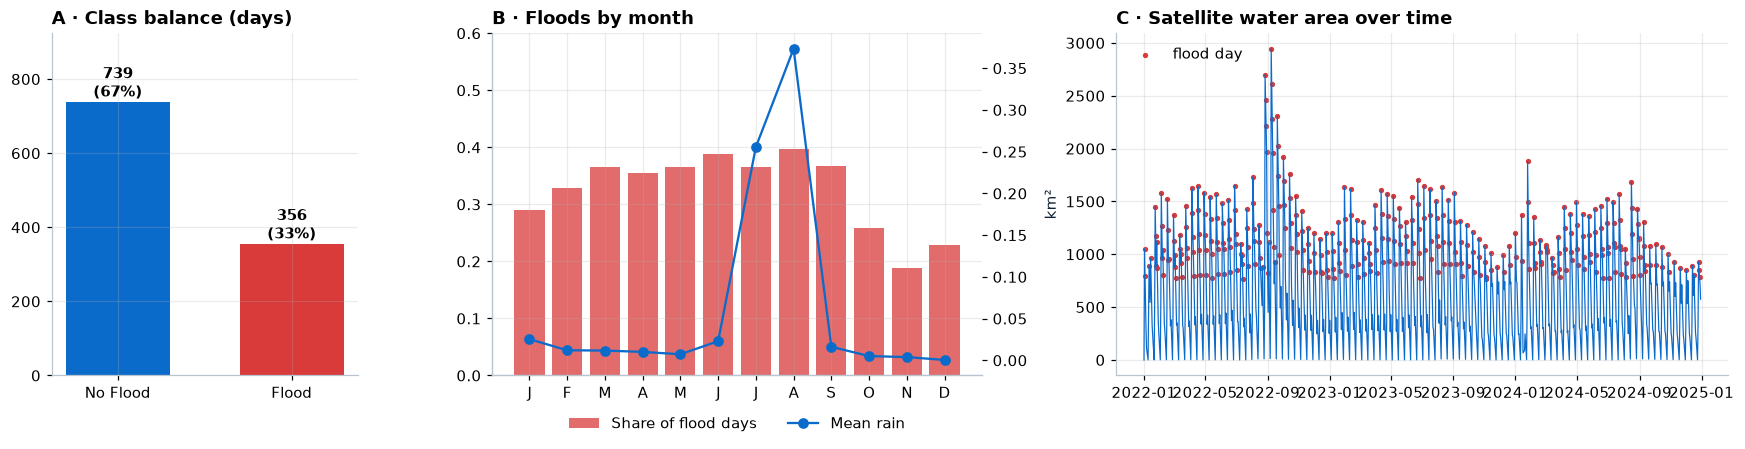

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1.6, 2]})
counts = df[TARGET].value_counts().reindex([0, 1])
axes[0].bar(["No Flood", "Flood"], counts.values, color=[C["blue"], C["red"]], width=0.6)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v}\n({v / counts.sum():.0%})", ha="center", va="bottom", fontweight="bold")
axes[0].set_title("A · Class balance (days)"); axes[0].set_ylim(0, counts.max() * 1.25)
monthly = df.groupby(df["date"].dt.month).agg(flood=(TARGET, "mean"), rain=("precipitation", "mean"))
axes[1].bar(monthly.index, monthly["flood"], color=C["red"], alpha=0.75, label="Share of flood days")
axes[1].set_xticks(range(1, 13), list("JFMAMJJASOND")); axes[1].set_ylim(0, 0.6); axes[1].set_title("B · Floods by month")
ax2 = axes[1].twinx(); ax2.plot(monthly.index, monthly["rain"], color=C["blue"], marker="o", label="Mean rain"); ax2.grid(False)
h = axes[1].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
axes[1].legend(h, [x.get_label() for x in h], loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
axes[2].plot(df["date"], df["water_area_km2"], color=C["blue"], lw=0.8)
fl = df[TARGET] == 1
axes[2].scatter(df.loc[fl, "date"], df.loc[fl, "water_area_km2"], color=C["red"], s=6, label="flood day")
axes[2].set_title("C · Satellite water area over time"); axes[2].set_ylabel("km²"); axes[2].legend(loc="upper left")
fig.tight_layout(); save(fig, "task4_overview"); plt.show()

### 4.5 How is a "flood day" defined? (the key discovery)
Comparing the water area on flood and non-flood days shows a **perfectly clean dividing line**: the label is essentially *"satellite water area above about 766 km²"*.

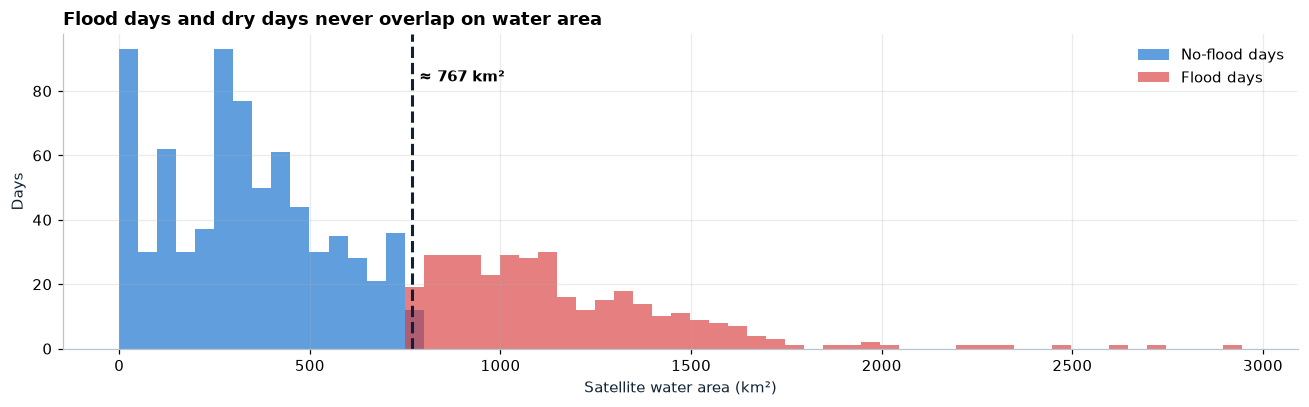

> **🔎 Task 4 findings**
>
> - 1,364 rows became **1,095 clean consecutive days** after merging 269 second satellite passes.
> - **33%** of days are flood days, peaking in **summer–monsoon months** (August highest at 40%, November lowest at 19%).
> - Every flood day has water area ≥ 768 km² and every dry day ≤ 766 km²: **the label is defined by satellite water area**. So asking *'is today a flood day?'* is trivial. The useful question is **'will tomorrow be a flood day?'** (Task 5).
> - Today's readings most linked to today's label: water_area_km2 (+0.84); rainfall is almost unrelated (+0.02), floods here follow the river water, not local rain.

In [6]:
FLOOD_MIN = df.loc[df[TARGET] == 1, "water_area_km2"].min()
DRY_MAX = df.loc[df[TARGET] == 0, "water_area_km2"].max()
fig, ax = plt.subplots(figsize=(12, 3.8))
bins = np.linspace(0, df["water_area_km2"].max(), 60)
ax.hist(df.loc[df[TARGET] == 0, "water_area_km2"], bins=bins, color=C["blue"], alpha=0.65, label="No-flood days")
ax.hist(df.loc[df[TARGET] == 1, "water_area_km2"], bins=bins, color=C["red"], alpha=0.65, label="Flood days")
ax.axvline((FLOOD_MIN + DRY_MAX) / 2, color=C["ink"], ls="--", lw=2)
ax.text((FLOOD_MIN + DRY_MAX) / 2 + 20, ax.get_ylim()[1] * 0.85, f"≈ {(FLOOD_MIN + DRY_MAX) / 2:.0f} km²", fontweight="bold")
ax.set_xlabel("Satellite water area (km²)"); ax.set_ylabel("Days"); ax.legend()
ax.set_title("Flood days and dry days never overlap on water area")
fig.tight_layout(); save(fig, "task4_label_definition"); plt.show()

corr = df[ENV + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
findings("Task 4 findings", [
    f"{len(raw):,} rows became **{len(df):,} clean consecutive days** after merging {len(raw) - len(df)} second satellite passes.",
    f"**{df[TARGET].mean():.0%}** of days are flood days, peaking in **summer–monsoon months** "
    f"({pd.Timestamp(2024, monthly['flood'].idxmax(), 1):%B} highest at {monthly['flood'].max():.0%}, {pd.Timestamp(2024, monthly['flood'].idxmin(), 1):%B} lowest at {monthly['flood'].min():.0%}).",
    f"Every flood day has water area ≥ {FLOOD_MIN:.0f} km² and every dry day ≤ {DRY_MAX:.0f} km²: **the label is defined by satellite water area**. "
    "So asking *'is today a flood day?'* is trivial. The useful question is **'will tomorrow be a flood day?'** (Task 5).",
    f"Today's readings most linked to today's label: {corr.index[0]} ({corr.iloc[0]:+.2f}); rainfall is almost unrelated "
    f"({corr['precipitation']:+.2f}), floods here follow the river water, not local rain.",
])

---
## Task 5 · Frame the task, engineer and select features, split by time
> **Syllabus:** extract, transform and encode features into an ML-ready format; select the most relevant features; split into training and testing sets; prepare the final feature matrix. *(LO 2.2)*

### 5.1 The forecasting task
For every day *t* we take the **7-day window t−6 … t** (everything known by the end of today) and predict the flood label of **day t+1**. Because the label is a threshold on water area, the honest test is whether we can see **tomorrow's** flood coming.

Split,Forecasts,First forecast day,Last forecast day,Flood share
Train,761,2022-01-08,2024-02-07,0.339
Validation,163,2024-02-08,2024-07-19,0.350
Test (unseen),164,2024-07-20,2024-12-30,0.238


Flood line learned from training days: 766.2 km²
Baseline 'tomorrow will be like today': test accuracy 81.7%, F1 0.615. Every model must beat this.


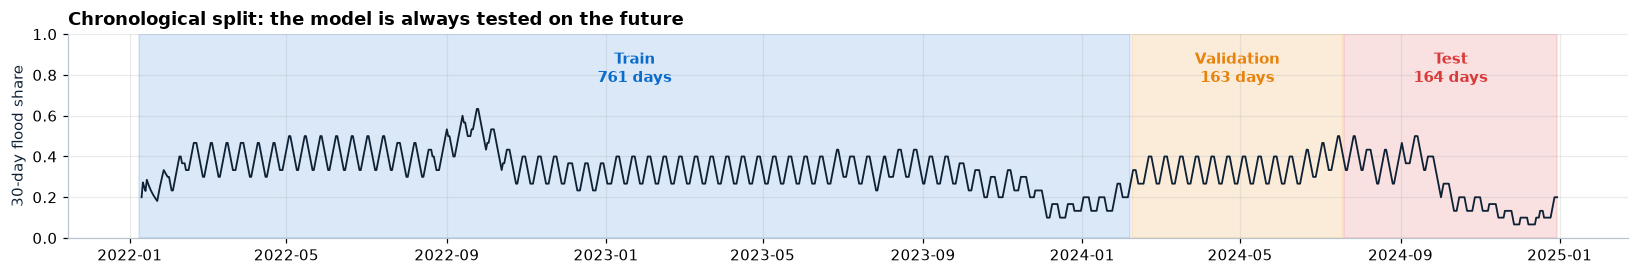

In [7]:
WINDOW = 7
TARGET_IDX = np.arange(WINDOW - 1, len(df) - 1)                 # window ends on t; we predict t + 1
n = len(TARGET_IDX); TRAIN_END, VAL_END = int(0.70 * n), int(0.85 * n)
idx_train, idx_val, idx_test = TARGET_IDX[:TRAIN_END], TARGET_IDX[TRAIN_END:VAL_END], TARGET_IDX[VAL_END:]
flood = df[TARGET].to_numpy()
y_train, y_val, y_test = flood[idx_train + 1], flood[idx_val + 1], flood[idx_test + 1]
dates_test = df["date"].iloc[idx_test + 1].reset_index(drop=True)      # the day being forecast

train_rows = df.iloc[: idx_train[-1] + 1]
FLOOD_LINE = float((train_rows.loc[train_rows[TARGET] == 0, "water_area_km2"].max()
                    + train_rows.loc[train_rows[TARGET] == 1, "water_area_km2"].min()) / 2)
split = pd.DataFrame([[name, len(ix), df["date"].iloc[ix[0] + 1].date(), df["date"].iloc[ix[-1] + 1].date(), flood[ix + 1].mean()]
                      for name, ix in [("Train", idx_train), ("Validation", idx_val), ("Test (unseen)", idx_test)]],
                     columns=["Split", "Forecasts", "First forecast day", "Last forecast day", "Flood share"])
display(table(split).hide(axis="index"))
print(f"Flood line learned from training days: {FLOOD_LINE:.1f} km²")

persist = (df["water_area_km2"].to_numpy()[idx_test] >= FLOOD_LINE).astype(int)       # "tomorrow = today"
print(f"Baseline 'tomorrow will be like today': test accuracy {accuracy_score(y_test, persist):.1%}, "
      f"F1 {f1_score(y_test, persist):.3f}. Every model must beat this.")

fig, ax = plt.subplots(figsize=(15, 2.6))
roll = df.set_index("date")[TARGET].rolling("30D", min_periods=10).mean()
ax.plot(roll.index, roll.values, color=C["ink"], lw=1.2)
for (name, ix), color in zip([("Train", idx_train), ("Validation", idx_val), ("Test", idx_test)], [C["blue"], C["orange"], C["red"]]):
    a, b = df["date"].iloc[ix[0] + 1], df["date"].iloc[ix[-1] + 1]
    ax.axvspan(a, b, color=color, alpha=0.15)
    ax.text(a + (b - a) / 2, 0.92, f"{name}\n{len(ix)} days", ha="center", va="top", color=color, fontweight="bold")
ax.set_ylim(0, 1); ax.set_ylabel("30-day flood share"); ax.set_title("Chronological split: the model is always tested on the future")
fig.tight_layout(); save(fig, "task5_split"); plt.show()

### 5.2 Features from each 7-day window
Each window becomes a small table: the **13 readings** for each day, the **season** (sine/cosine of the day of year, so 31 Dec sits next to 1 Jan), and two counters that capture how floods behave here:
* **flood_streak**: how many days the water has already been above the flood line (floods here usually last 4–5 days),
* **dry_streak**: how many days since it dropped below the line.

Everything is computed **from the window alone**, so the deployed website can rebuild it from any 7 uploaded days.

In [8]:
SEASON = ["day_of_year_sin", "day_of_year_cos"]
DAILY = ENV + SEASON + ["flood_streak", "dry_streak"]
LSTM_INPUTS = ["water_area_km2", "water_area_change", "flood_streak", "dry_streak",
               "precipitation", "soil_moisture", "day_of_year_sin", "day_of_year_cos"]
ML_DAILY = ENV + SEASON                                         # flattened over the 7 days for the ML models

def window_frame(win: pd.DataFrame) -> pd.DataFrame:
    """7 consecutive days → per-day feature table (identical code runs on the website)."""
    f = win[ENV].reset_index(drop=True).astype(float).copy()
    doy = pd.to_datetime(win["date"]).dt.day_of_year.to_numpy()
    f["day_of_year_sin"], f["day_of_year_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    wet = (f["water_area_km2"].to_numpy() >= FLOOD_LINE).astype(int)
    fs, ds, a, b = [], [], 0, 0
    for w in wet:
        a, b = (a + 1, 0) if w else (0, b + 1)
        fs.append(a); ds.append(b)
    f["flood_streak"], f["dry_streak"] = fs, ds
    return f

def flat(frame: pd.DataFrame) -> pd.Series:
    """Per-day table → one row: reading@d-6 … reading@d0 (d0 = today)."""
    return pd.Series({f"{c}@d{i - WINDOW + 1}": frame[c].iloc[i] for c in ML_DAILY for i in range(WINDOW)})

frames = [window_frame(df.iloc[t - WINDOW + 1: t + 1]) for t in TARGET_IDX]
X_all = pd.DataFrame([flat(f) for f in frames])
X_train_all, X_val_all, X_test_all = X_all.iloc[:TRAIN_END], X_all.iloc[TRAIN_END:VAL_END], X_all.iloc[VAL_END:]
print(f"ML matrix: {X_all.shape[1]} features ({len(ML_DAILY)} daily readings × {WINDOW} days) for {len(X_all)} forecasts")
display(frames[0].round(3))

ML matrix: 105 features (15 daily readings × 7 days) for 1088 forecasts


,precipitation,soil_moisture,temperature,humidity,pressure,wind_speed,evaporation,water_area_km2,water_area_change,precip_3day_avg,precip_7day_avg,temp_3day_avg,soil_3day_avg,day_of_year_sin,day_of_year_cos,flood_streak,dry_streak
0,0.017,0.121,15.017,60.272,100881.327,2.390,-0.000,0.000,0.000,0.017,0.017,15.017,0.121,0.017,1.000,0,1
1,0.005,0.114,15.427,56.802,100752.320,3.203,-0.000,1051.165,1051.165,0.011,0.011,15.222,0.118,0.034,0.999,1,0
2,0.102,0.108,16.144,57.422,100545.919,2.545,-0.000,796.452,-254.713,0.037,0.032,15.666,0.112,0.052,0.999,2,0
3,1.417,0.164,15.177,70.497,100431.610,1.858,-0.000,541.739,-254.713,0.508,0.309,15.583,0.129,0.069,0.998,0,1
4,0.059,0.327,15.078,84.949,100229.507,0.579,-0.001,287.026,-254.713,0.526,0.267,15.466,0.200,0.086,0.996,0,2
5,0.496,0.316,15.427,85.013,100190.650,1.406,-0.001,111.612,-175.414,0.657,0.300,15.227,0.269,0.103,0.995,0,3
6,0.015,0.338,12.671,80.090,100223.107,2.341,-0.001,74.493,-37.119,0.335,0.370,14.508,0.324,0.120,0.993,0,4


### 5.3 Feature selection, validated by cross-validation
Two independent rankings on the training windows, **mutual information** (statistical) and **Random-Forest importance** (model-based), are averaged. Instead of guessing how many to keep, **time-series cross-validation** (always training on the past and testing on the next block) picks the size that forecasts best.

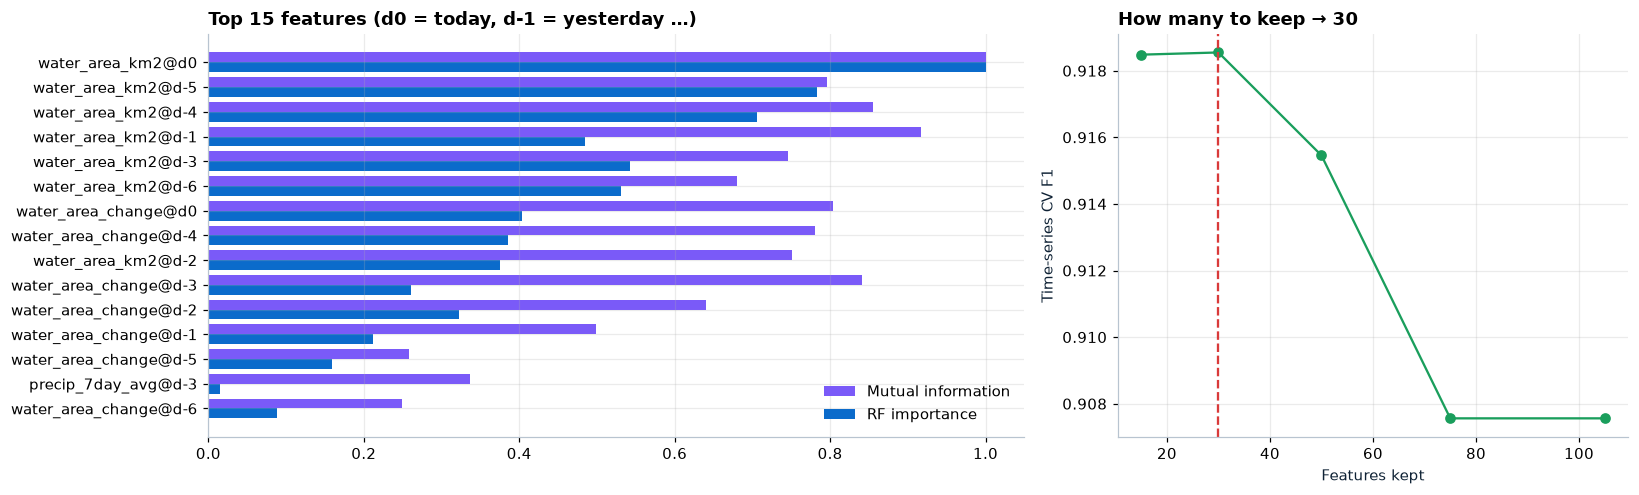

> **🔎 Task 5 findings**
>
> - Task: **forecast tomorrow** from a 7-day window · 761 / 163 / 164 train / validation / test forecasts, split by date.
> - Baseline 'tomorrow = today' scores **81.7%** on the test months: the bar to beat.
> - Kept **30 of 105** features (chosen by time-series CV). Top features: water_area_km2@d0, water_area_km2@d-5, water_area_km2@d-4.
> - Water-area features carry **87%** of the selected importance; rain matters little, consistent with Task 4.

In [9]:
mi = mutual_info_classif(X_train_all, y_train, random_state=SEED)
rf_rank = RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=SEED, n_jobs=-1).fit(X_train_all, y_train)
ranking = pd.DataFrame({"Mutual information": mi, "RF importance": rf_rank.feature_importances_}, index=X_all.columns)
ranking["Combined"] = (ranking / ranking.max()).mean(axis=1)
ranking = ranking.sort_values("Combined", ascending=False)

def boosted(seed=SEED):
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=250, class_weight="balanced", random_state=seed)

def cv_f1(cols):
    X, y = X_all.iloc[:VAL_END][cols].to_numpy(), flood[TARGET_IDX[:VAL_END] + 1]
    return np.mean([f1_score(y[b], boosted().fit(X[a], y[a]).predict(X[b])) for a, b in TimeSeriesSplit(4).split(X)])

sizes = [15, 30, 50, 75, len(ranking)]
cv = pd.Series({k: cv_f1(ranking.index[:k].tolist()) for k in sizes}, name="CV F1")
K = int(cv.idxmax()); SELECTED = ranking.index[:K].tolist()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
top = ranking.head(15).iloc[::-1]
axes[0].barh(top.index, top["Mutual information"] / ranking["Mutual information"].max(), height=0.4, color=C["purple"], label="Mutual information", align="edge")
axes[0].barh(top.index, top["RF importance"] / ranking["RF importance"].max(), height=-0.4, color=C["blue"], label="RF importance", align="edge")
axes[0].set_title("Top 15 features (d0 = today, d-1 = yesterday …)"); axes[0].legend(loc="lower right")
axes[1].plot(cv.index, cv.values, marker="o", color=C["green"]); axes[1].axvline(K, color=C["red"], ls="--")
axes[1].set_xlabel("Features kept"); axes[1].set_ylabel("Time-series CV F1"); axes[1].set_title(f"How many to keep → {K}")
fig.tight_layout(); save(fig, "task5_feature_selection"); plt.show()

X_train, X_val, X_test = X_train_all[SELECTED], X_val_all[SELECTED], X_test_all[SELECTED]
water_share = sum(ranking.loc[SELECTED, "Combined"][[c.startswith("water") for c in SELECTED]]) / ranking.loc[SELECTED, "Combined"].sum()
findings("Task 5 findings", [
    f"Task: **forecast tomorrow** from a 7-day window · {len(idx_train)} / {len(idx_val)} / {len(idx_test)} train / validation / test forecasts, split by date.",
    f"Baseline 'tomorrow = today' scores **{accuracy_score(y_test, persist):.1%}** on the test months: the bar to beat.",
    f"Kept **{K} of {len(ranking)}** features (chosen by time-series CV). Top features: {', '.join(SELECTED[:3])}.",
    f"Water-area features carry **{water_share:.0%}** of the selected importance; rain matters little, consistent with Task 4.",
])

---
## Task 6 · Train, evaluate and analyse machine-learning models
> **Syllabus:** select supervised and unsupervised algorithms; train; evaluate with accuracy, precision, recall, F1 and the confusion matrix; analyse errors. *(LO 2.3)*

Five families are compared against two baselines. Each model is chosen by **time-series cross-validation on train + validation**, never on the test months; the decision threshold of each is also chosen by CV.

In [10]:
def scaled(model):
    return Pipeline([("scale", StandardScaler()), ("model", model)])

ml_models = {
    "Logistic Regression": scaled(LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "SVM (RBF)": scaled(SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED)),
    "Gradient Boosting": boosted(),
}
y_tv = flood[TARGET_IDX[:VAL_END] + 1]; X_tv = X_all.iloc[:VAL_END][SELECTED].to_numpy()
GRID = np.round(np.arange(0.20, 0.81, 0.02), 2)

def cv_probs(make):
    """Out-of-fold probabilities from 4 expanding time-series folds."""
    oof = np.full(len(y_tv), np.nan)
    for a, b in TimeSeriesSplit(4).split(X_tv):
        oof[b] = make().fit(X_tv[a], y_tv[a]).predict_proba(X_tv[b])[:, 1]
    return oof

rows, ml_prob, ml_th = [], {}, {}
for name, model in ml_models.items():
    oof = cv_probs(lambda: sklearn.base.clone(model)); m = ~np.isnan(oof)
    th = max(GRID, key=lambda t: f1_score(y_tv[m], oof[m] >= t))
    model.fit(X_train, y_train); prob = model.predict_proba(X_test)[:, 1]
    ml_prob[name], ml_th[name] = prob, th
    rows.append({"Model": name, "CV F1": f1_score(y_tv[m], oof[m] >= th), "Threshold": th, **scores(y_test, prob, th)})
rows.append({"Model": "Baseline: tomorrow = today", "CV F1": np.nan, "Threshold": np.nan, **scores(y_test, None, pred=persist)})
rows.append({"Model": "Baseline: always 'no flood'", "CV F1": np.nan, "Threshold": np.nan, **scores(y_test, None, pred=np.zeros_like(y_test))})
ml_results = pd.DataFrame(rows).set_index("Model")
BEST_ML = ml_results.drop(index=[i for i in ml_results.index if i.startswith("Baseline")])["CV F1"].idxmax()
print(f"Best on cross-validation: {BEST_ML}  ·  test metrics use the untouched test months")
display(table(ml_results, gradient=["F1", "Accuracy"]))

Best on cross-validation: Gradient Boosting  ·  test metrics use the untouched test months


,CV F1,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,,
Logistic Regression,0.903,0.640,0.829,0.590,0.923,0.720,0.925
Decision Tree,0.886,0.200,0.945,0.895,0.872,0.883,0.919
Random Forest,0.891,0.440,0.927,0.800,0.923,0.857,0.984
SVM (RBF),0.869,0.440,0.860,0.643,0.923,0.758,0.936
Gradient Boosting,0.923,0.640,0.963,1.000,0.846,0.917,0.993
Baseline: tomorrow = today,nan,nan,0.817,0.615,0.615,0.615,nan
Baseline: always 'no flood',nan,nan,0.762,0.000,0.000,0.000,nan


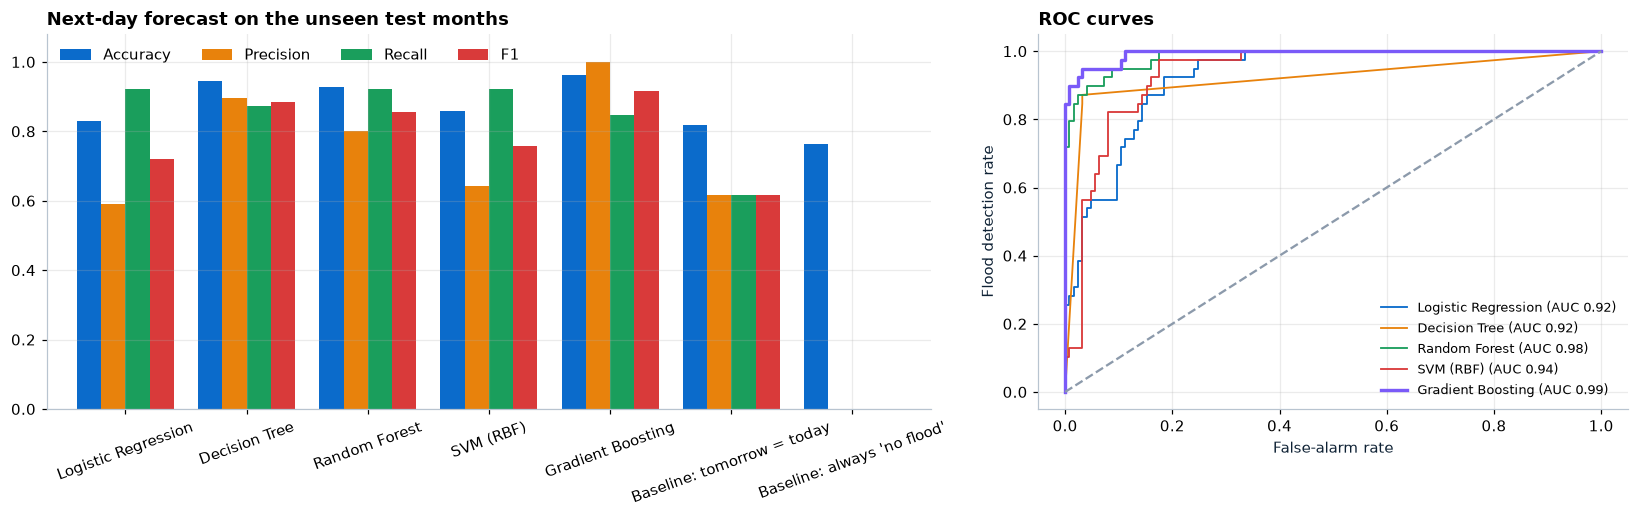

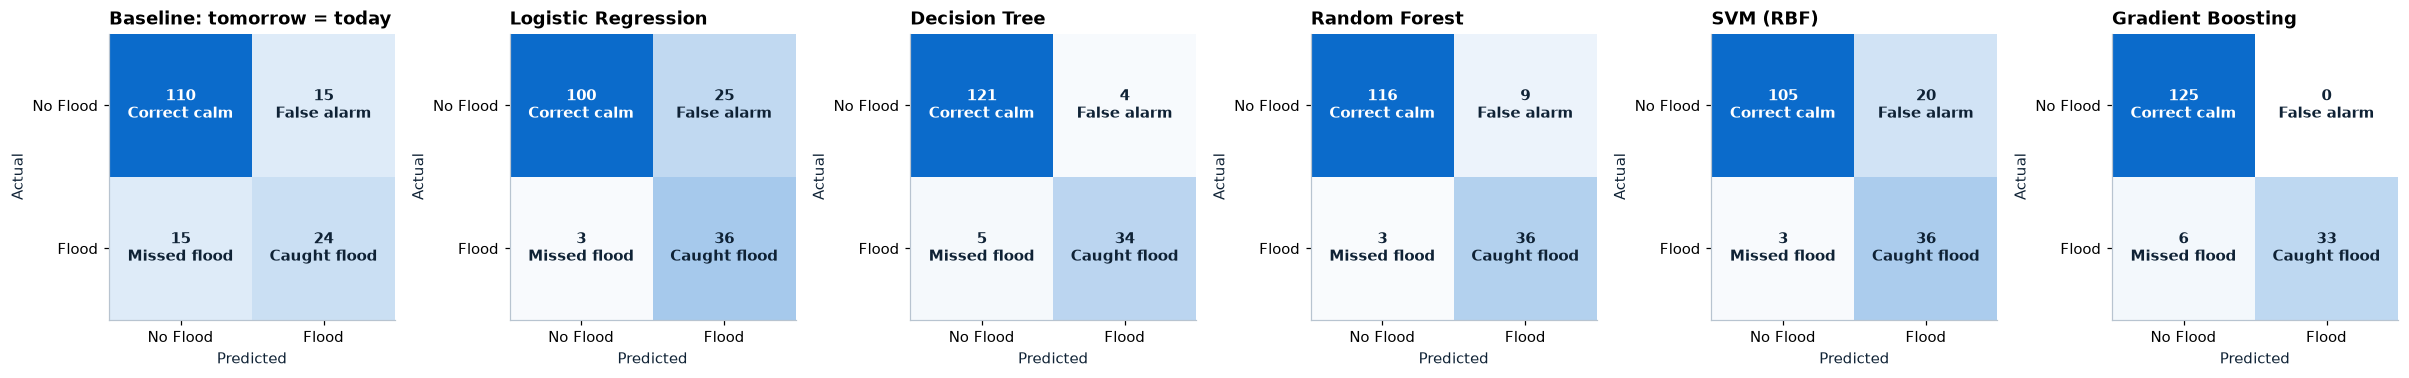

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ml_results[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", ax=axes[0], width=0.8, ylim=(0, 1.08))
axes[0].tick_params(axis="x", rotation=20); axes[0].set_xlabel(""); axes[0].legend(ncol=4, loc="upper left")
axes[0].set_title("Next-day forecast on the unseen test months")
for name, prob in ml_prob.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, lw=2.2 if name == BEST_ML else 1.2, label=f"{name} (AUC {roc_auc_score(y_test, prob):.2f})")
axes[1].plot([0, 1], [0, 1], ls="--", color=C["grey"]); axes[1].legend(loc="lower right", fontsize=8.5)
axes[1].set_xlabel("False-alarm rate"); axes[1].set_ylabel("Flood detection rate"); axes[1].set_title("ROC curves")
fig.tight_layout(); save(fig, "task6_model_comparison"); plt.show()

fig, axes = plt.subplots(1, 6, figsize=(22, 3.6))
plot_cm(axes[0], y_test, persist, "Baseline: tomorrow = today")
for ax, (name, prob) in zip(axes[1:], ml_prob.items()):
    plot_cm(ax, y_test, (prob >= ml_th[name]).astype(int), name)
fig.tight_layout(); save(fig, "task6_confusion_matrices"); plt.show()

### Error analysis: what does the best model get wrong?
A **missed flood** (false negative) leaves people unwarned; a **false alarm** costs money and trust.

In [12]:
best_pred = (ml_prob[BEST_ML] >= ml_th[BEST_ML]).astype(int)
today = df.iloc[idx_test].reset_index(drop=True)
errors = pd.DataFrame({"Forecast for": dates_test.dt.date, "Water today (km²)": today["water_area_km2"].round(0),
                       "Change today": today["water_area_change"].round(0), "Flooded today": (today["water_area_km2"] >= FLOOD_LINE).map({True: "yes", False: "no"}),
                       "Actual tomorrow": np.where(y_test == 1, "Flood", "No flood"), "P(flood)": ml_prob[BEST_ML].round(3)})
errors["Error"] = np.select([(y_test == 1) & (best_pred == 0), (y_test == 0) & (best_pred == 1)], ["Missed flood", "False alarm"], "")
wrong = errors[errors["Error"] != ""]
print(f"{BEST_ML}: {len(wrong)} mistakes on {len(errors)} forecasts → {(wrong['Error'] == 'Missed flood').sum()} missed floods, "
      f"{(wrong['Error'] == 'False alarm').sum()} false alarms")
display(table(wrong, precision=2).hide(axis="index"))

Gradient Boosting: 6 mistakes on 164 forecasts → 6 missed floods, 0 false alarms


Forecast for,Water today (km²),Change today,Flooded today,Actual tomorrow,P(flood),Error
2024-08-20,952.00,-244.00,yes,Flood,0.06,Missed flood
2024-09-02,977.00,-177.00,yes,Flood,0.53,Missed flood
2024-09-12,843.00,-233.00,yes,Flood,0.49,Missed flood
2024-12-17,612.00,-140.00,no,Flood,0.37,Missed flood
2024-12-27,928.00,593.00,yes,Flood,0.31,Missed flood
2024-12-28,856.00,-72.00,yes,Flood,0.04,Missed flood


### SHAP: why does the gradient-boosting model forecast a flood?
Each dot is one test forecast; right = pushes towards *flood tomorrow*, colour = the feature's value (red high, blue low).

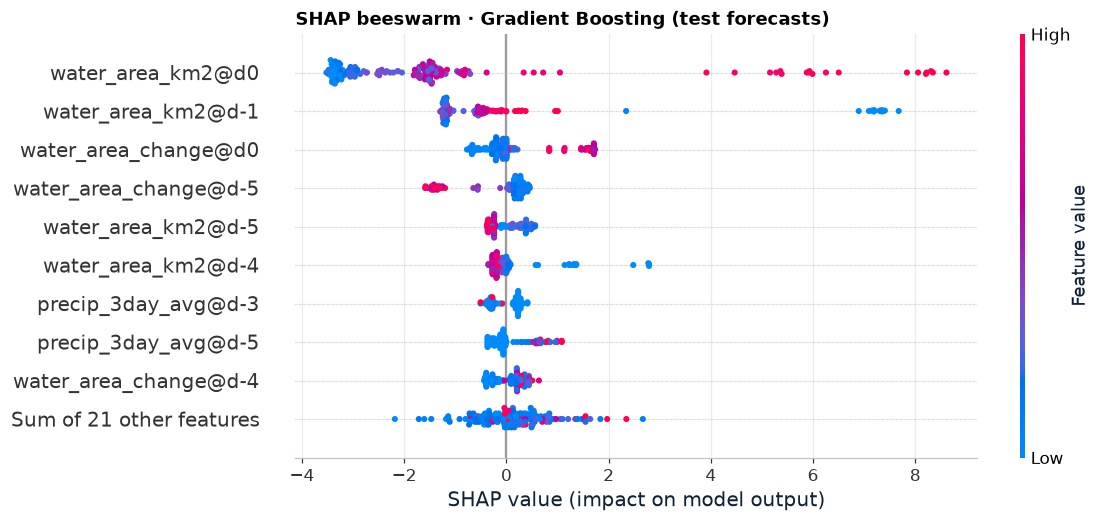

In [13]:
gb = ml_models["Gradient Boosting"]
gb_shap = shap.TreeExplainer(gb)(X_test)
plt.figure(); shap.plots.beeswarm(gb_shap, max_display=10, show=False, plot_size=(10, 5))
plt.title("SHAP beeswarm · Gradient Boosting (test forecasts)", loc="left", fontweight="bold")
save(plt.gcf(), "task6_shap_beeswarm"); plt.show()
gb_rank = pd.Series(np.abs(gb_shap.values).mean(0), index=SELECTED).sort_values(ascending=False)

### Sensitivity check and unsupervised learning
What if the models could **not** see the satellite water readings? And do the days fall into natural groups without labels (K-Means, Agglomerative)?

,F1 with water,F1 weather only
Random Forest,0.857,0.169
Gradient Boosting,0.917,0.234


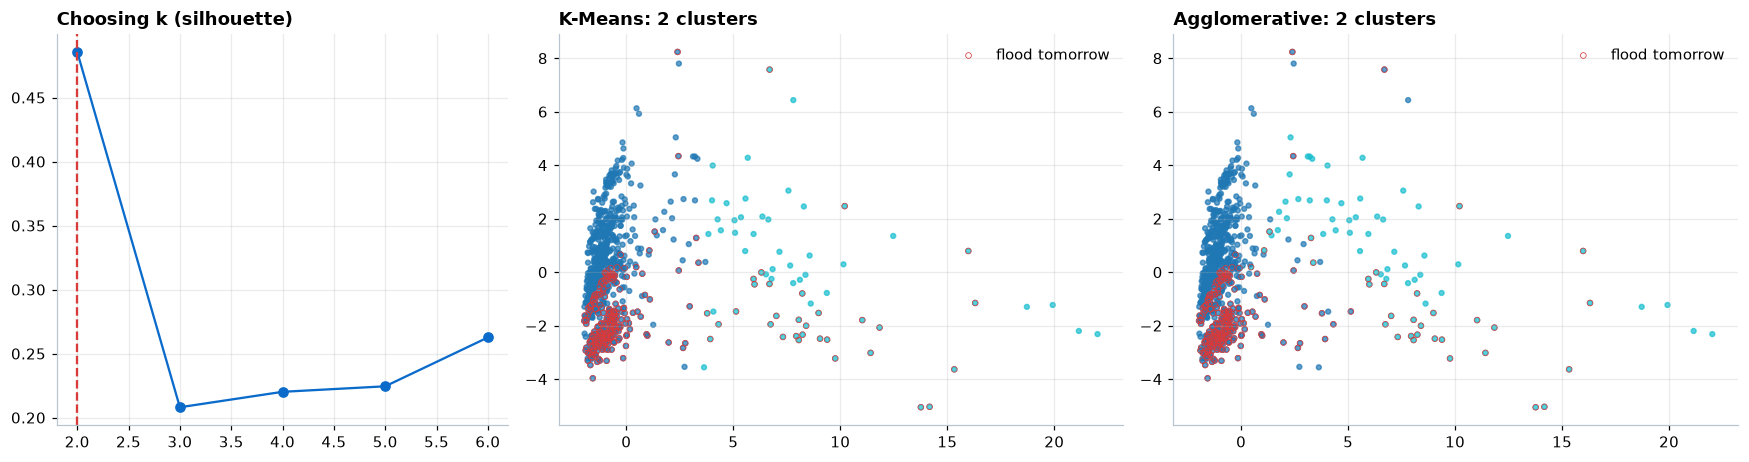

> **🔎 Task 6 findings**
>
> - **Gradient Boosting** wins on cross-validation: test accuracy **96.3%**, F1 0.917, recall 84.6%, vs 81.7% for 'tomorrow = today'.
> - SHAP: the forecast leans on **water_area_km2@d0** and **water_area_km2@d-1**: where the water is today and how it is moving.
> - Without water readings, F1 collapses (gradient boosting 0.92 → 0.23): local weather alone cannot forecast these river floods.
> - Unsupervised: k = 2 clusters agree weakly with floods (ARI 0.03), so flood days are not a simple natural group.

In [14]:
no_water = [c for c in SELECTED if not c.startswith("water")]
abl = {}
for name in ["Random Forest", "Gradient Boosting"]:
    m = sklearn.base.clone(ml_models[name]).fit(X_train[no_water], y_train)
    abl[name] = (ml_results.loc[name, "F1"], f1_score(y_test, m.predict(X_test[no_water])))
abl = pd.DataFrame(abl, index=["F1 with water", "F1 weather only"]).T
display(table(abl))

Xs = StandardScaler().fit_transform(X_train)
sil = {k: silhouette_score(Xs, KMeans(k, n_init=10, random_state=SEED).fit_predict(Xs)) for k in range(2, 7)}
K_CL = max(sil, key=sil.get)
km = KMeans(K_CL, n_init=10, random_state=SEED).fit_predict(Xs); ag = AgglomerativeClustering(n_clusters=K_CL, linkage="ward").fit_predict(Xs)
pca = PCA(2, random_state=SEED).fit(Xs); Pc = pca.transform(Xs)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [0.8, 1, 1]})
axes[0].plot(list(sil), list(sil.values()), marker="o"); axes[0].axvline(K_CL, color=C["red"], ls="--"); axes[0].set_title("Choosing k (silhouette)")
for ax, lab, name in [(axes[1], km, "K-Means"), (axes[2], ag, "Agglomerative")]:
    ax.scatter(Pc[:, 0], Pc[:, 1], c=lab, cmap="tab10", s=10, alpha=0.7)
    ax.scatter(Pc[y_train == 1, 0], Pc[y_train == 1, 1], facecolors="none", edgecolors=C["red"], s=14, lw=0.5, label="flood tomorrow")
    ax.set_title(f"{name}: {K_CL} clusters"); ax.legend(loc="upper right")
fig.tight_layout(); save(fig, "task6_clustering"); plt.show()

best = ml_results.loc[BEST_ML]
findings("Task 6 findings", [
    f"**{BEST_ML}** wins on cross-validation: test accuracy **{best['Accuracy']:.1%}**, F1 {best['F1']:.3f}, recall {best['Recall']:.1%}, "
    f"vs {accuracy_score(y_test, persist):.1%} for 'tomorrow = today'.",
    f"SHAP: the forecast leans on **{gb_rank.index[0]}** and **{gb_rank.index[1]}**: where the water is today and how it is moving.",
    f"Without water readings, F1 collapses (gradient boosting {abl.loc['Gradient Boosting', 'F1 with water']:.2f} → "
    f"{abl.loc['Gradient Boosting', 'F1 weather only']:.2f}): local weather alone cannot forecast these river floods.",
    f"Unsupervised: k = {K_CL} clusters agree weakly with floods (ARI {adjusted_rand_score(y_train, km):.2f}), so flood days are not a simple natural group.",
])

---
## Task 7 · Design, tune and train a deep-learning model (LSTM)
> **Syllabus:** design an advanced deep-learning architecture (CNN, RNN or **LSTM**) suited to the data type; train with appropriate hyper-parameters and regularisation. *(LO 3.1)*

The data is a **daily time series**, so an LSTM reads each window **day by day** with a memory. It gets 8 focused inputs (water, its change, the two flood counters, rain, soil and season); a dense network that sees the same numbers without order is the baseline.

LSTM input: (samples, days, inputs) → train (761, 7, 8) · validation (163, 7, 8) · test (164, 7, 8)


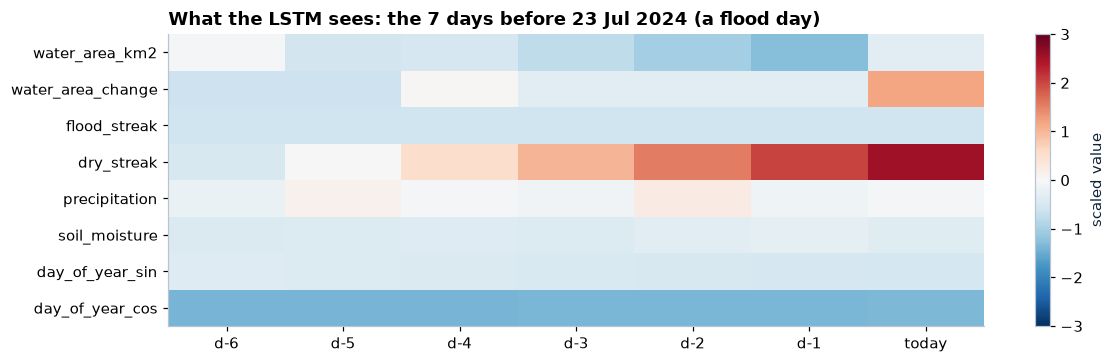

In [15]:
stack = pd.concat([frames[i] for i in range(TRAIN_END)])[LSTM_INPUTS]
seq_imputer, seq_scaler = SimpleImputer(strategy="median").fit(stack), StandardScaler()
seq_scaler.fit(seq_imputer.transform(stack))
S_all = np.stack([seq_scaler.transform(seq_imputer.transform(f[LSTM_INPUTS])) for f in frames]).astype(np.float32)
S_train, S_val, S_test = S_all[:TRAIN_END], S_all[TRAIN_END:VAL_END], S_all[VAL_END:]
print(f"LSTM input: (samples, days, inputs) → train {S_train.shape} · validation {S_val.shape} · test {S_test.shape}")

ex = int(np.argmax(y_test))
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(S_test[ex].T, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_yticks(range(len(LSTM_INPUTS)), LSTM_INPUTS); ax.set_xticks(range(WINDOW), [f"d{i - WINDOW + 1}" if i < WINDOW - 1 else "today" for i in range(WINDOW)])
ax.grid(False); fig.colorbar(im, ax=ax, label="scaled value")
ax.set_title(f"What the LSTM sees: the 7 days before {dates_test[ex]:%d %b %Y} (a flood day)")
fig.tight_layout(); save(fig, "task7_input_window"); plt.show()

In [16]:
class DenseBaseline(nn.Module):
    def __init__(self, n_inputs, hidden=32, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(WINDOW * n_inputs, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

class FloodLSTM(nn.Module):
    def __init__(self, n_inputs, hidden=16, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(n_inputs, hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)
    def embed(self, x):
        _, (h, _) = self.lstm(x)
        return h[-1]
    def forward(self, x):
        return self.head(self.dropout(self.embed(x))).squeeze(-1)

def train_model(model, Xa, ya, Xv, yv, lr=1e-3, max_epochs=200, patience=20, seed=SEED):
    """Class-weighted BCE, Adam + weight decay, gradient clipping, early stopping on validation loss."""
    set_seed(seed)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((ya == 0).sum() / max((ya == 1).sum(), 1), dtype=torch.float32))
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loader = DataLoader(TensorDataset(torch.from_numpy(Xa), torch.from_numpy(ya.astype(np.float32))), batch_size=32,
                        shuffle=True, generator=torch.Generator().manual_seed(seed))
    xv, yvt = torch.from_numpy(Xv), torch.from_numpy(yv.astype(np.float32))
    hist, best, best_state, best_epoch, wait = {"train": [], "val": []}, np.inf, None, 0, 0
    for epoch in range(1, max_epochs + 1):
        model.train(); losses = []
        for xb, yb in loader:
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(xv), yvt).item()
        hist["train"].append(np.mean(losses)); hist["val"].append(val_loss)
        if val_loss < best - 1e-4:
            best, best_epoch, wait = val_loss, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    return model, hist, best_epoch

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(X))).numpy()

### Hyper-parameter tuning
Validation F1 is almost saturated (the validation months are easy), so configurations are compared on **validation loss**, a finer signal.

✓ Dense baseline: best epoch 118, validation loss 0.0386


✓ LSTM 16 units · dropout 0.1: best epoch 188, validation loss 0.0159


✓ LSTM 32 units · dropout 0.2: best epoch 143, validation loss 0.0143


✓ LSTM 32 units · dropout 0.3: best epoch 37, validation loss 0.1086


✓ LSTM 64 units · dropout 0.3: best epoch 196, validation loss 0.0253


,Best epoch,Validation loss,Validation F1,Validation ROC-AUC
Model,,,,
Dense baseline,118,0.039,0.982,1.000
LSTM 16 units · dropout 0.1,188,0.016,1.000,1.000
LSTM 32 units · dropout 0.2,143,0.014,1.000,1.000
LSTM 32 units · dropout 0.3,37,0.109,0.932,0.996
LSTM 64 units · dropout 0.3,196,0.025,1.000,1.000


Selected: LSTM 32 units · dropout 0.2


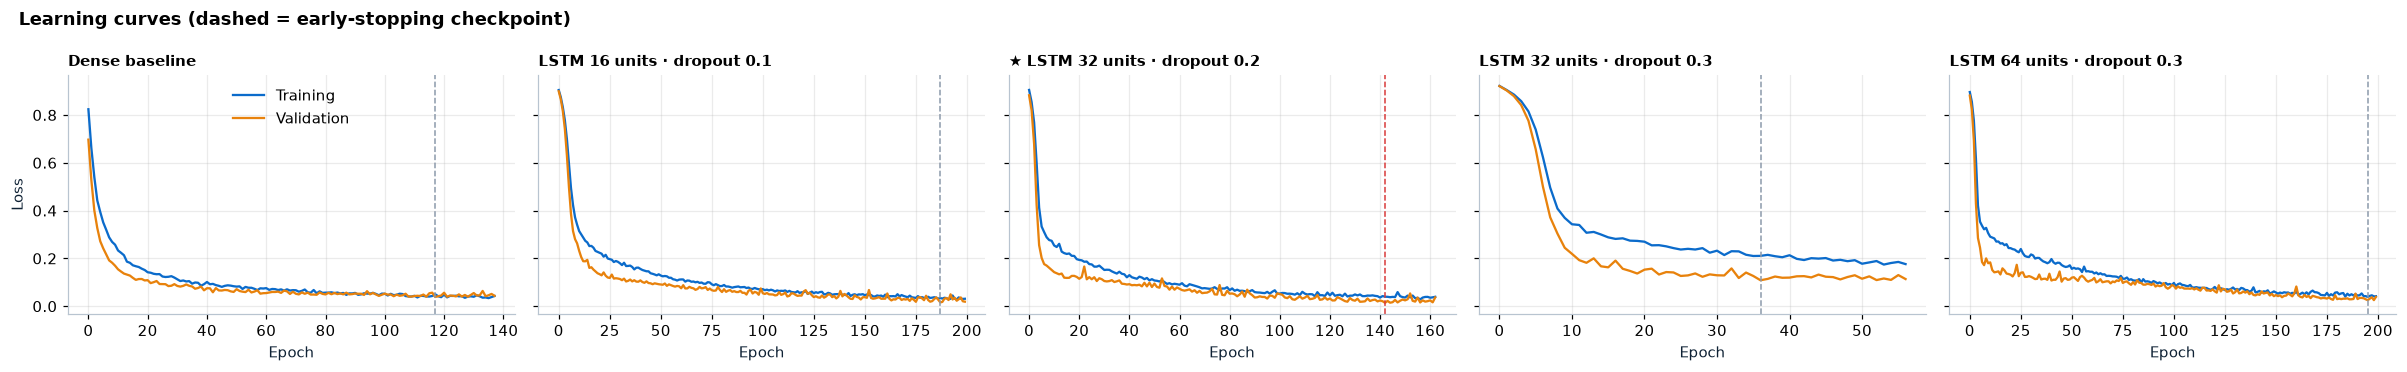

In [17]:
candidates = [("Dense baseline", DenseBaseline, dict(hidden=32, dropout=0.2), 1e-3),
              ("LSTM 16 units · dropout 0.1", FloodLSTM, dict(hidden=16, dropout=0.1), 1e-3),
              ("LSTM 32 units · dropout 0.2", FloodLSTM, dict(hidden=32, dropout=0.2), 1e-3),
              ("LSTM 32 units · dropout 0.3", FloodLSTM, dict(hidden=32, dropout=0.3), 5e-4),
              ("LSTM 64 units · dropout 0.3", FloodLSTM, dict(hidden=64, dropout=0.3), 5e-4)]
dl_models, histories, rows = {}, {}, []
for i, (name, cls, params, lr) in enumerate(candidates):
    set_seed(SEED + i)
    model, hist, be = train_model(cls(len(LSTM_INPUTS), **params), S_train, y_train, S_val, y_val, lr=lr, seed=SEED + i)
    dl_models[name], histories[name] = model, (hist, be)
    pv = predict(model, S_val)
    rows.append({"Model": name, "Best epoch": be, "Validation loss": min(hist["val"]), "Validation F1": f1_score(y_val, pv >= 0.5),
                 "Validation ROC-AUC": roc_auc_score(y_val, pv), "params": params, "lr": lr})
    print(f"✓ {name}: best epoch {be}, validation loss {min(hist['val']):.4f}")
tuning = pd.DataFrame(rows).set_index("Model")
BEST_LSTM = tuning.drop("Dense baseline")["Validation loss"].idxmin()
lstm, dense = dl_models[BEST_LSTM], dl_models["Dense baseline"]
LSTM_PARAMS, LSTM_LR = tuning.loc[BEST_LSTM, "params"], tuning.loc[BEST_LSTM, "lr"]
display(table(tuning.drop(columns=["params", "lr"]), gradient=["Validation loss"]))
print(f"Selected: {BEST_LSTM}")

fig, axes = plt.subplots(1, 5, figsize=(22, 3.4), sharey=True)
for ax, (name, (hist, be)) in zip(axes, histories.items()):
    ax.plot(hist["train"], label="Training", color=C["blue"]); ax.plot(hist["val"], label="Validation", color=C["orange"])
    ax.axvline(be - 1, color=C["red"] if name == BEST_LSTM else C["grey"], ls="--", lw=1)
    ax.set_title(("★ " if name == BEST_LSTM else "") + name, fontsize=9.5); ax.set_xlabel("Epoch")
axes[0].set_ylabel("Loss"); axes[0].legend()
fig.suptitle("Learning curves (dashed = early-stopping checkpoint)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "task7_learning_curves"); plt.show()

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Dense baseline,0.915,0.766,0.923,0.837,0.981
LSTM 32 units · dropout 0.2,0.921,0.810,0.872,0.840,0.957
Baseline: tomorrow = today,0.817,0.615,0.615,0.615,nan


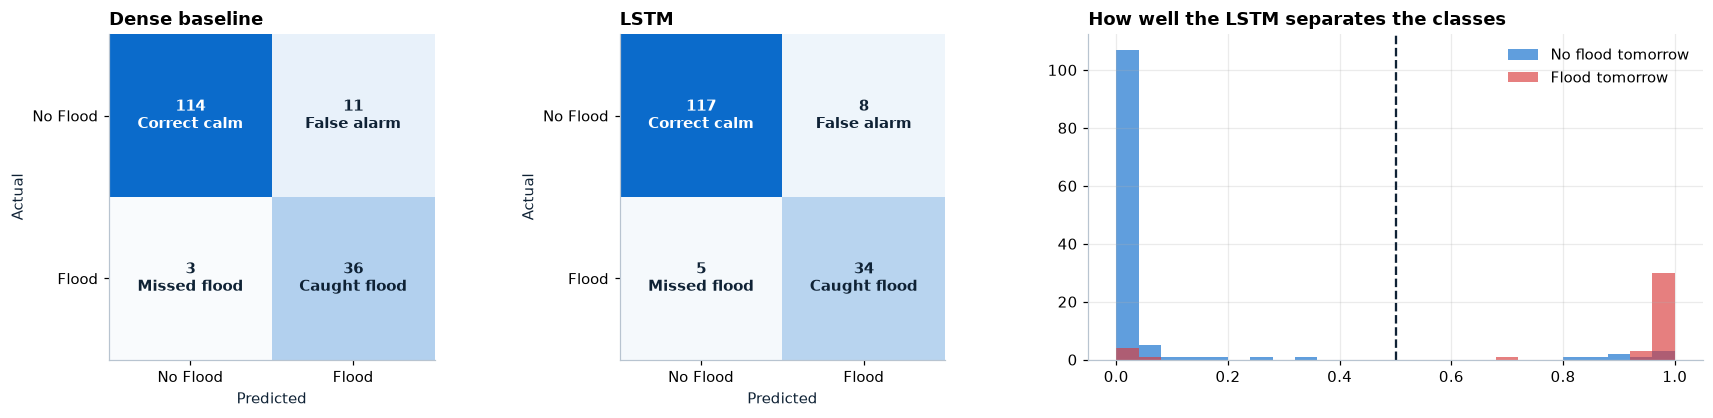

> **🔎 Task 7 findings**
>
> - Selected **LSTM 32 units · dropout 0.2** (5,409 weights) on validation loss; test accuracy 92.1%, F1 0.840 vs dense baseline F1 0.837.
> - Regularisation: dropout, L2 weight decay, gradient clipping and early stopping. Curves stop before validation loss climbs.
> - With only 761 training weeks, the LSTM does not beat gradient boosting on its own; its value is a second, time-aware opinion and interpretability over days (Tasks 8–9).

In [18]:
p_dense, p_lstm = predict(dense, S_test), predict(lstm, S_test)
dl_results = pd.DataFrame([{"Model": "Dense baseline", **scores(y_test, p_dense)}, {"Model": BEST_LSTM, **scores(y_test, p_lstm)},
                           {"Model": "Baseline: tomorrow = today", **scores(y_test, None, pred=persist)}]).set_index("Model")
display(table(dl_results, gradient=["F1"]))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.5]})
plot_cm(axes[0], y_test, (p_dense >= 0.5).astype(int), "Dense baseline"); plot_cm(axes[1], y_test, (p_lstm >= 0.5).astype(int), "LSTM")
bins = np.linspace(0, 1, 26)
axes[2].hist(p_lstm[y_test == 0], bins=bins, alpha=0.65, color=C["blue"], label="No flood tomorrow")
axes[2].hist(p_lstm[y_test == 1], bins=bins, alpha=0.65, color=C["red"], label="Flood tomorrow")
axes[2].axvline(0.5, color=C["ink"], ls="--"); axes[2].legend(); axes[2].set_title("How well the LSTM separates the classes")
fig.tight_layout(); save(fig, "task7_test_results"); plt.show()
findings("Task 7 findings", [
    f"Selected **{BEST_LSTM}** ({sum(p.numel() for p in lstm.parameters()):,} weights) on validation loss; test accuracy "
    f"{dl_results.loc[BEST_LSTM, 'Accuracy']:.1%}, F1 {dl_results.loc[BEST_LSTM, 'F1']:.3f} vs dense baseline F1 {dl_results.loc['Dense baseline', 'F1']:.3f}.",
    "Regularisation: dropout, L2 weight decay, gradient clipping and early stopping. Curves stop before validation loss climbs.",
    f"With only {len(y_train)} training weeks, the LSTM does not beat gradient boosting on its own; its value is a second, "
    "time-aware opinion and interpretability over days (Tasks 8–9).",
])

---
## Task 8 · Interpret the deep-learning model
> **Syllabus:** apply interpretability and visualisation methods (feature maps, activation visualisation, attention); compare with the basic model. *(LO 3.2)*

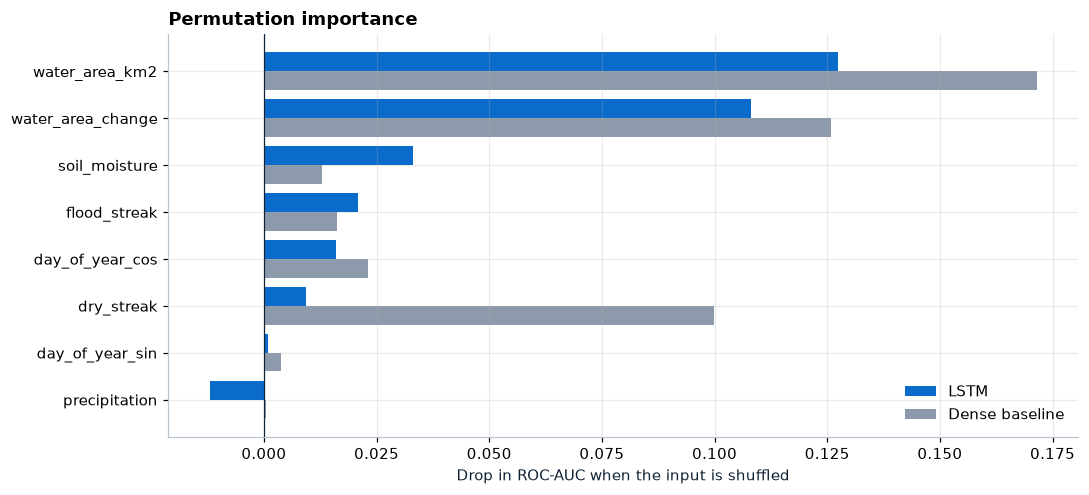

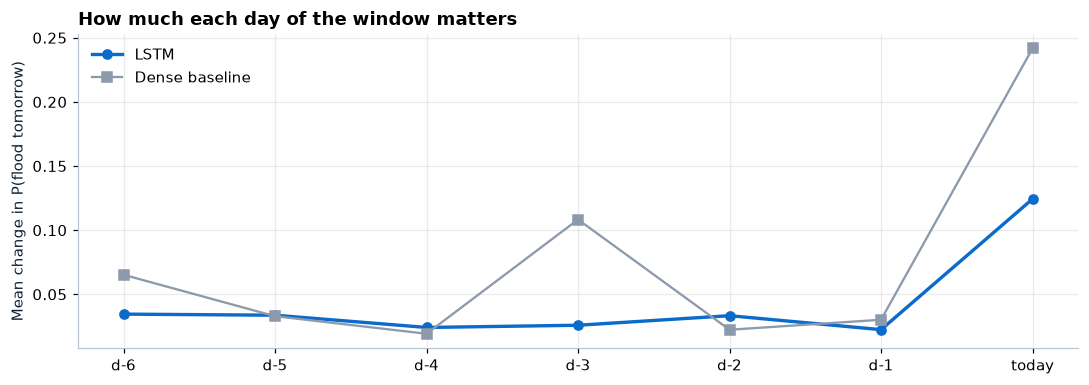

In [19]:
rng = np.random.default_rng(SEED); perm_rows = []
for model_name, model in [("Dense baseline", dense), ("LSTM", lstm)]:
    base = roc_auc_score(y_test, predict(model, S_test))
    for j, feature in enumerate(LSTM_INPUTS):
        drops = []
        for _ in range(5):
            Xp = S_test.copy(); Xp[:, :, j] = S_test[rng.permutation(len(S_test)), :, j]
            drops.append(base - roc_auc_score(y_test, predict(model, Xp)))
        perm_rows.append({"Model": model_name, "Input": feature, "AUC drop": np.mean(drops)})
perm = pd.DataFrame(perm_rows).pivot(index="Input", columns="Model", values="AUC drop").sort_values("LSTM")
fig, ax = plt.subplots(figsize=(10, 4.6)); yp = np.arange(len(perm))
ax.barh(yp + 0.2, perm["LSTM"], height=0.4, color=C["blue"], label="LSTM")
ax.barh(yp - 0.2, perm["Dense baseline"], height=0.4, color=C["grey"], label="Dense baseline")
ax.set_yticks(yp, perm.index); ax.axvline(0, color=C["ink"], lw=0.8); ax.legend(loc="lower right")
ax.set_xlabel("Drop in ROC-AUC when the input is shuffled"); ax.set_title("Permutation importance")
fig.tight_layout(); save(fig, "task8_permutation"); plt.show()

day_labels = [f"d{i - WINDOW + 1}" for i in range(WINDOW - 1)] + ["today"]
time_rows = []
for model_name, model in [("Dense baseline", dense), ("LSTM", lstm)]:
    base = predict(model, S_test)
    for d in range(WINDOW):
        Xa = S_test.copy(); Xa[:, d, :] = 0.0
        time_rows.append({"Model": model_name, "Day": day_labels[d], "Δ": np.abs(predict(model, Xa) - base).mean()})
time_imp = pd.DataFrame(time_rows).pivot(index="Day", columns="Model", values="Δ").reindex(day_labels)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(day_labels, time_imp["LSTM"], marker="o", lw=2.2, color=C["blue"], label="LSTM")
ax.plot(day_labels, time_imp["Dense baseline"], marker="s", color=C["grey"], label="Dense baseline")
ax.set_ylabel("Mean change in P(flood tomorrow)"); ax.legend(); ax.set_title("How much each day of the window matters")
fig.tight_layout(); save(fig, "task8_time_steps"); plt.show()

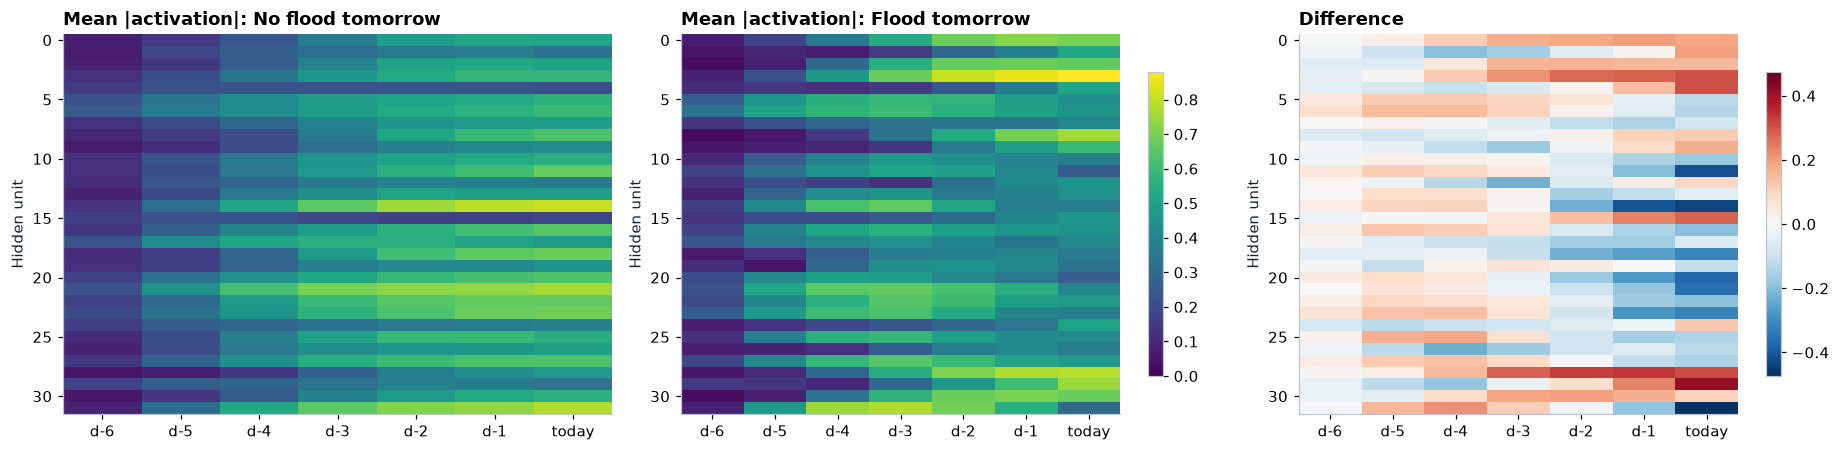

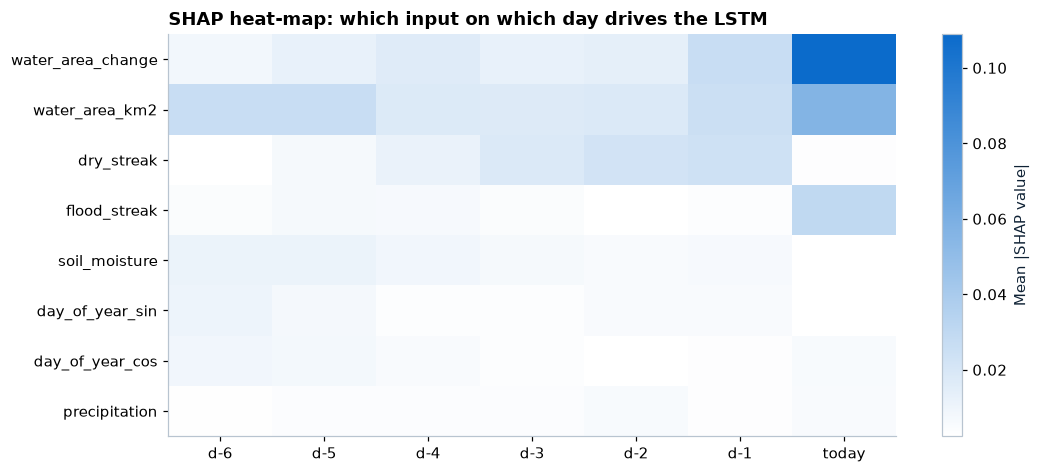

> **🔎 Task 8 findings**
>
> - Permutation and SHAP agree: the LSTM relies most on **water_area_change** and **water_area_km2**.
> - **today** influences the forecast most; earlier days add trend context.
> - Hidden units respond differently before flood days, mostly on the last days of the window.
> - These methods show what the model uses, not what physically causes floods.

In [20]:
with torch.no_grad():
    acts = lstm.lstm(torch.from_numpy(S_test))[0].numpy()
a_f, a_c = np.abs(acts[y_test == 1]).mean(0), np.abs(acts[y_test == 0]).mean(0); diff = a_f - a_c
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2)); vmax = max(a_f.max(), a_c.max())
for ax, dat, title in [(axes[0], a_c, "No flood tomorrow"), (axes[1], a_f, "Flood tomorrow")]:
    im = ax.imshow(dat.T, aspect="auto", cmap="viridis", vmin=0, vmax=vmax); ax.set_title(f"Mean |activation|: {title}")
im2 = axes[2].imshow(diff.T, aspect="auto", cmap="RdBu_r", vmin=-np.abs(diff).max(), vmax=np.abs(diff).max()); axes[2].set_title("Difference")
for ax in axes:
    ax.set_xticks(range(WINDOW), day_labels); ax.set_ylabel("Hidden unit"); ax.grid(False)
fig.colorbar(im, ax=axes[1], shrink=0.8); fig.colorbar(im2, ax=axes[2], shrink=0.8)
fig.tight_layout(); save(fig, "task8_activations"); plt.show()

class ProbabilityOutput(nn.Module):
    def __init__(self, model):
        super().__init__(); self.model = model
    def forward(self, x):
        return torch.sigmoid(self.model(x)).unsqueeze(-1)
background = torch.from_numpy(S_train[np.random.default_rng(SEED).choice(len(S_train), 100, replace=False)])
explainer = shap.GradientExplainer(ProbabilityOutput(lstm).eval(), background)
lstm_shap = explainer.shap_values(torch.from_numpy(S_test))
lstm_shap = np.asarray(lstm_shap[0] if isinstance(lstm_shap, list) else lstm_shap)
if lstm_shap.ndim == 4:
    lstm_shap = lstm_shap[..., 0]
heat = np.abs(lstm_shap).mean(0).T; order = np.argsort(heat.sum(1))[::-1]
fig, ax = plt.subplots(figsize=(10, 4.4))
im = ax.imshow(heat[order], cmap=CM_CMAP, aspect="auto")
ax.set_yticks(range(len(order)), [LSTM_INPUTS[i] for i in order]); ax.set_xticks(range(WINDOW), day_labels); ax.grid(False)
fig.colorbar(im, ax=ax, label="Mean |SHAP value|"); ax.set_title("SHAP heat-map: which input on which day drives the LSTM")
fig.tight_layout(); save(fig, "task8_shap_heatmap"); plt.show()
lstm_rank = pd.Series(np.abs(lstm_shap).sum(1).mean(0), index=LSTM_INPUTS).sort_values(ascending=False)
findings("Task 8 findings", [
    f"Permutation and SHAP agree: the LSTM relies most on **{lstm_rank.index[0]}** and **{lstm_rank.index[1]}**.",
    f"**{time_imp['LSTM'].idxmax()}** influences the forecast most; earlier days add trend context.",
    "Hidden units respond differently before flood days, mostly on the last days of the window.",
    "These methods show what the model uses, not what physically causes floods.",
])

---
## Task 9 · Integrate DL + ML → AI rules into one early-warning system
> **Syllabus:** integrate Deep Learning, Machine Learning and Artificial Intelligence for decision making; test with representative inputs. *(LO 4.1)*

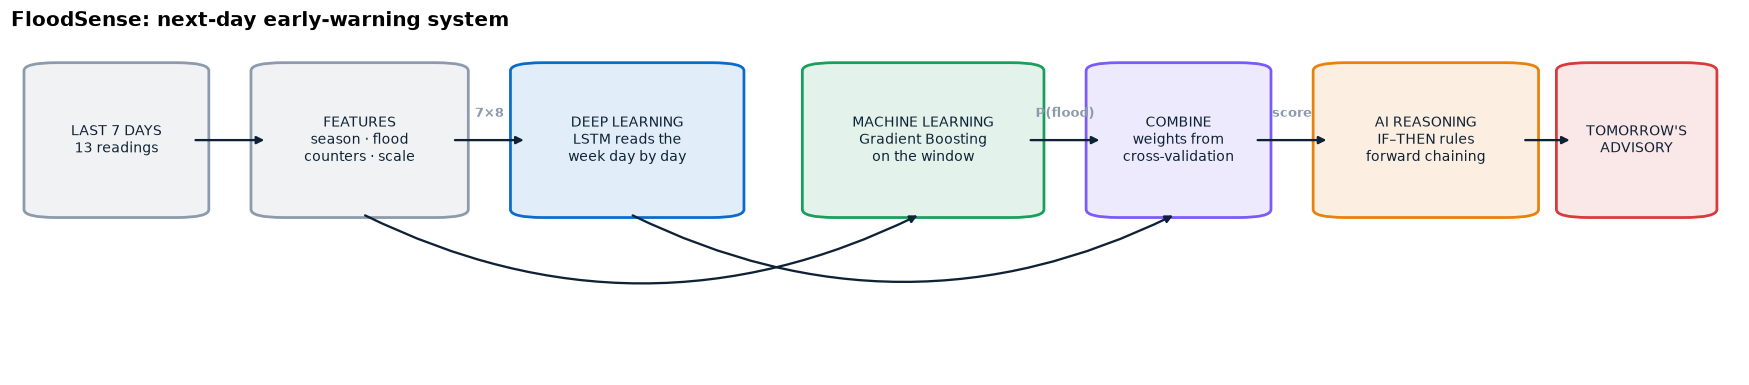

In [21]:
#@title 🧭 System architecture diagram
def draw_flow(ax, boxes, arrows, title):
    for key, (x, y, w, h, text, color) in boxes.items():
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.012,rounding_size=0.02",
                                    fc=color + "1F", ec=color, lw=1.8))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9.2, color=C["ink"])
    for a, b, label, style in arrows:
        xa, ya, wa, ha, *_ = boxes[a]; xb, yb, wb, hb, *_ = boxes[b]
        start, end = (xa + wa, ya + ha / 2), (xb, yb + hb / 2)
        if style == "below":
            start, end = (xa + wa / 2, ya), (xb + wb / 2, yb)
        ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", lw=1.5, color=C["ink"],
                    shrinkA=4, shrinkB=4, connectionstyle="arc3,rad=0.25" if style == "below" else "arc3"))
        if label:
            mx = (start[0] + end[0]) / 2
            my = min(ya, yb) - 0.25 if style == "below" else start[1] + 0.05
            ax.text(mx, my, label, ha="center", va="bottom", fontsize=8.5, color=C["grey"], fontweight="bold")
    tops = [y + h for _, y, _, h, *_ in boxes.values()]
    bottoms = [y for _, y, *_ in boxes.values()]
    has_below = any(style == "below" for *_, style in arrows)
    ax.set_xlim(-0.02, 1.045); ax.set_ylim(min(bottoms) - (0.40 if has_below else 0.08), max(tops) + 0.08)
    ax.axis("off"); ax.set_title(title, fontsize=13)


fig, ax = plt.subplots(figsize=(16, 3.6))
boxes = {
    "in":  (0.00, 0.50, 0.090, 0.36, "LAST 7 DAYS\n13 readings", C["grey"]),
    "pre": (0.140, 0.50, 0.110, 0.36, "FEATURES\nseason · flood\ncounters · scale", C["grey"]),
    "dl":  (0.300, 0.50, 0.120, 0.36, "DEEP LEARNING\nLSTM reads the\nweek day by day", C["blue"]),
    "ml":  (0.480, 0.50, 0.125, 0.36, "MACHINE LEARNING\nGradient Boosting\non the window", C["green"]),
    "mix": (0.655, 0.50, 0.090, 0.36, "COMBINE\nweights from\ncross-validation", C["purple"]),
    "ai":  (0.795, 0.50, 0.115, 0.36, "AI REASONING\nIF–THEN rules\nforward chaining", C["orange"]),
    "out": (0.945, 0.50, 0.075, 0.36, "TOMORROW'S\nADVISORY", C["red"]),
}
arrows = [("in", "pre", "", ""), ("pre", "dl", "7×8", ""), ("pre", "ml", "", "below"), ("dl", "mix", "", "below"),
          ("ml", "mix", "P(flood)", ""), ("mix", "ai", "score", ""), ("ai", "out", "", "")]
draw_flow(ax, boxes, arrows, "FloodSense: next-day early-warning system")
fig.tight_layout(); save(fig, "task9_architecture"); plt.show()

### 9.1 Choose the blend and thresholds by time-series cross-validation
Both models are re-trained on 4 expanding slices of the past and scored on the following block. The weight of each model and the decision thresholds that forecast those *future* blocks best are kept; the test months stay untouched.

**Why F2, not F1?** For an early warning, a **missed flood is worse than a false alarm**. F2 counts recall (floods caught) twice as much as precision, so the thresholds lean towards warning.

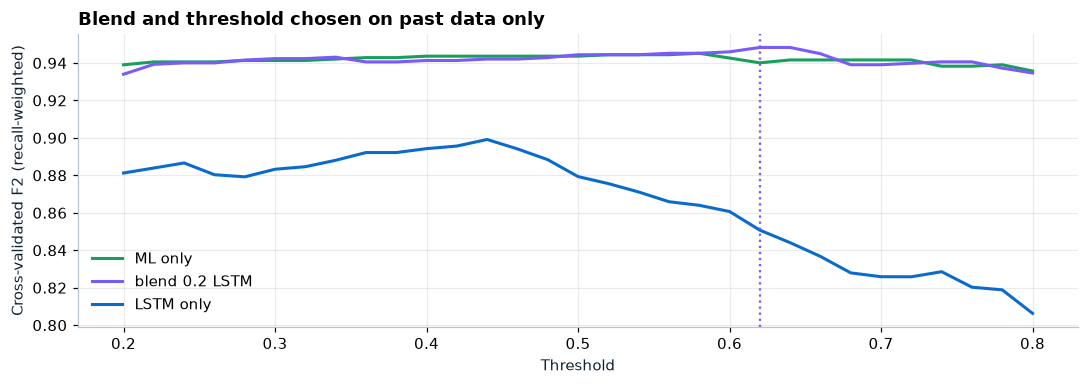

Blend: 20% LSTM + 80% Gradient Boosting · thresholds: LSTM 0.44 · ML 0.58 · system 0.62


In [22]:
def lstm_factory():
    return FloodLSTM(len(LSTM_INPUTS), **LSTM_PARAMS)

oof_dl, oof_ml = np.full(VAL_END, np.nan), np.full(VAL_END, np.nan)
for a, b in TimeSeriesSplit(4).split(np.arange(VAL_END)):
    cut = int(len(a) * 0.85); ia, iv = a[:cut], a[cut:]
    m, _, _ = train_model(lstm_factory(), S_all[ia], y_tv[ia], S_all[iv], y_tv[iv], lr=LSTM_LR)
    oof_dl[b] = predict(m, S_all[b])
    oof_ml[b] = sklearn.base.clone(ml_models[BEST_ML]).fit(X_tv[a], y_tv[a]).predict_proba(X_tv[b])[:, 1]
mk = ~np.isnan(oof_dl); yo = y_tv[mk]
f2 = lambda y, p: fbeta_score(y, p, beta=2, zero_division=0)
W_DL, TH_SYS = max([(w, t) for w in np.round(np.arange(0, 1.01, 0.1), 1) for t in GRID],
                   key=lambda wt: (f2(yo, wt[0] * oof_dl[mk] + (1 - wt[0]) * oof_ml[mk] >= wt[1]), -abs(wt[1] - 0.5)))
TH = {"dl": max(GRID, key=lambda t: f2(yo, oof_dl[mk] >= t)), "ml": max(GRID, key=lambda t: f2(yo, oof_ml[mk] >= t)), "sys": TH_SYS}
fig, ax = plt.subplots(figsize=(10, 3.6))
for w, color in [(0.0, C["green"]), (W_DL, C["purple"]), (1.0, C["blue"])]:
    ax.plot(GRID, [f2(yo, w * oof_dl[mk] + (1 - w) * oof_ml[mk] >= t) for t in GRID], color=color, lw=2,
            label=f"{'ML only' if w == 0 else 'LSTM only' if w == 1 else f'blend {w:.1f} LSTM'}")
ax.axvline(TH_SYS, color=C["purple"], ls=":"); ax.set_xlabel("Threshold"); ax.set_ylabel("Cross-validated F2 (recall-weighted)"); ax.legend()
ax.set_title("Blend and threshold chosen on past data only")
fig.tight_layout(); save(fig, "task9_thresholds"); plt.show()
print(f"Blend: {W_DL:.0%} LSTM + {1 - W_DL:.0%} {BEST_ML} · thresholds: LSTM {TH['dl']:.2f} · ML {TH['ml']:.2f} · system {TH['sys']:.2f}")

### 9.2 AI reasoning: rules for tomorrow (forward chaining)
Facts are gathered (the combined score and warning signs from **today's** readings), then rules are checked from most to least severe; the first that fires gives tomorrow's advisory.
* **Warning** = the system predicts a flood (score above its flood line).
* **Watch** = a precaution: no flood is predicted, but the score is at least **15 %**. Getting ready is cheap and being surprised is costly, so any real doubt is flagged. The table shows how often each score band flooded in cross-validation; Task 10 reports how Watch days turned out on the test months.
* **Monitor** = no flood expected, but something needs watching (flooded today, water close to the line, heavy rain, very wet soil or a rapid rise; 90th percentiles of the training period).

In [23]:
RULE_LEVELS = {
    "heavy_rain": float(train_rows["precipitation"].quantile(0.90)),
    "wet_soil": float(train_rows["soil_moisture"].quantile(0.90)),
    "rapid_rise": float(train_rows.loc[train_rows["water_area_change"] > 0, "water_area_change"].quantile(0.90)),
    "near_line": 0.85 * FLOOD_LINE,
}
WATCH_LEVEL = 0.15
oof_sys = W_DL * oof_dl[mk] + (1 - W_DL) * oof_ml[mk]
band = pd.DataFrame({"Score band": pd.cut(oof_sys, [0, 0.05, WATCH_LEVEL, TH["sys"], 1], include_lowest=True), "Flood tomorrow": yo})
display(band.groupby("Score band", observed=True)["Flood tomorrow"].agg(["size", "mean"]).rename(
    columns={"size": "Days (cross-validated)", "mean": "Share that flooded"}).style.format({"Share that flooded": "{:.0%}"}))

RULES = [
    ("R1", "FLOOD WARNING", "The system predicts a flood tomorrow (score above the flood line)",
     lambda f: f["score"] >= TH["sys"]),
    ("R2", "FLOOD WATCH", "A real chance of flooding tomorrow (score ≥ 15 %)",
     lambda f: f["score"] >= WATCH_LEVEL),
    ("R3", "MONITOR", "Flooded today, water near the line, or any other warning sign",
     lambda f: f["flooded_today"] or f["near_line"] or f["heavy_rain"] or f["wet_soil"] or f["rapid_rise"]),
    ("R4", "LOW RISK", "No rule above fired", lambda f: True),
]

def gather_facts(today, pdl, pml):
    water = today["water_area_km2"]
    return {"dl_flood": pdl >= TH["dl"], "ml_flood": pml >= TH["ml"], "score": W_DL * pdl + (1 - W_DL) * pml,
            "flooded_today": water >= FLOOD_LINE, "near_line": RULE_LEVELS["near_line"] <= water < FLOOD_LINE,
            "heavy_rain": today["precipitation"] >= RULE_LEVELS["heavy_rain"], "wet_soil": today["soil_moisture"] >= RULE_LEVELS["wet_soil"],
            "rapid_rise": today["water_area_change"] >= RULE_LEVELS["rapid_rise"]}

def forward_chain(facts):
    for rule_id, advisory, text, test in RULES:
        if test(facts):
            return advisory, rule_id, text

display(pd.DataFrame([(r, a, t) for r, a, t, _ in RULES], columns=["Rule", "Advisory for tomorrow", "Fires when…"]).style.hide(axis="index"))
display(pd.DataFrame({"Warning level": RULE_LEVELS}).style.format(precision=3))

,Days (cross-validated),Share that flooded
Score band,,
"(-0.001, 0.05]",371,1%
"(0.05, 0.15]",54,7%
"(0.15, 0.62]",53,2%
"(0.62, 1.0]",258,90%


Rule,Advisory for tomorrow,Fires when…
R1,FLOOD WARNING,The system predicts a flood tomorrow (score above the flood line)
R2,FLOOD WATCH,A real chance of flooding tomorrow (score ≥ 15 %)
R3,MONITOR,"Flooded today, water near the line, or any other warning sign"
R4,LOW RISK,No rule above fired


,Warning level
heavy_rain,0.090
wet_soil,0.226
rapid_rise,1170.703
near_line,651.273


### 9.3 The integrated system as one reusable component

In [24]:
best_ml_model = ml_models[BEST_ML]

class FloodSenseSystem:
    """validate → features → LSTM + ML → blend → rules. Input: the last 7 days; output: tomorrow's advisory."""
    def validate_window(self, window):
        if not isinstance(window, pd.DataFrame):
            raise TypeError("Input must be a table (pandas DataFrame).")
        missing = [c for c in ["date"] + ENV if c not in window.columns]
        if missing:
            raise ValueError(f"Missing columns: {missing}")
        if len(window) != WINDOW:
            raise ValueError(f"Exactly {WINDOW} daily rows are required, got {len(window)}.")
        w = window.copy(); w["date"] = pd.to_datetime(w["date"], errors="coerce")
        if w["date"].isna().any():
            raise ValueError("Invalid date found; use YYYY-MM-DD.")
        if w["date"].duplicated().any():
            raise ValueError("Duplicate dates found.")
        w = w.sort_values("date").reset_index(drop=True)
        if not w["date"].diff().dropna().dt.days.eq(1).all():
            raise ValueError("Dates must be consecutive days.")
        w[ENV] = w[ENV].apply(pd.to_numeric, errors="coerce")
        if w[ENV].isna().all().any():
            raise ValueError(f"Columns with no numeric values: {w[ENV].columns[w[ENV].isna().all()].tolist()}")
        w[ENV] = w[ENV].fillna(w[ENV].median())
        return w

    def predict_window(self, window):
        w = self.validate_window(window); frame = window_frame(w)
        s = seq_scaler.transform(seq_imputer.transform(frame[LSTM_INPUTS])).astype(np.float32)[None]
        pdl = float(predict(lstm, s)[0])
        pml = float(best_ml_model.predict_proba(flat(frame)[SELECTED].to_frame().T)[0, 1])
        facts = gather_facts(w.iloc[-1], pdl, pml)
        advisory, rule_id, rule_text = forward_chain(facts)
        return {"today": w["date"].iloc[-1].date(), "for": (w["date"].iloc[-1] + pd.Timedelta(days=1)).date(),
                "P(LSTM)": pdl, "P(ML)": pml, "Combined": facts["score"],
                "Prediction": "Flood" if facts["score"] >= TH["sys"] else "No Flood", "Advisory": advisory, "Rule": rule_id, "Why": rule_text,
                "Triggers": [k for k in ["flooded_today", "near_line", "heavy_rain", "wet_soil", "rapid_rise"] if facts[k]]}

system = FloodSenseSystem()
def window_ending(i):
    return df.iloc[i - WINDOW + 1: i + 1][["date"] + ENV]
results = pd.DataFrame([system.predict_window(window_ending(i)) for i in idx_test])
results["Actual"] = np.where(y_test == 1, "Flood", "No Flood")
p_sys = results["Combined"].to_numpy(); y_sys = (results["Prediction"] == "Flood").astype(int).to_numpy()
assert np.allclose(results["P(LSTM)"], p_lstm, atol=1e-5)
print(f"Ran the full system on {len(results)} unseen 7-day windows ✓")
display(results.head(8).round(3))

Ran the full system on 164 unseen 7-day windows ✓


,today,for,P(LSTM),P(ML),Combined,Prediction,Advisory,Rule,Why,Triggers,Actual
0,2024-07-19,2024-07-20,0.000,0.000,0.000,No Flood,LOW RISK,R4,No rule above fired,[],No Flood
1,2024-07-20,2024-07-21,0.000,0.000,0.000,No Flood,MONITOR,R3,"Flooded today, water near the line, or any oth...",[heavy_rain],No Flood
2,2024-07-21,2024-07-22,0.000,0.000,0.000,No Flood,LOW RISK,R4,No rule above fired,[],No Flood
3,2024-07-22,2024-07-23,0.999,0.996,0.997,Flood,FLOOD WARNING,R1,The system predicts a flood tomorrow (score ab...,[],Flood
4,2024-07-23,2024-07-24,1.000,0.999,0.999,Flood,FLOOD WARNING,R1,The system predicts a flood tomorrow (score ab...,[flooded_today],Flood
5,2024-07-24,2024-07-25,0.999,0.999,0.999,Flood,FLOOD WARNING,R1,The system predicts a flood tomorrow (score ab...,[flooded_today],Flood
6,2024-07-25,2024-07-26,0.975,0.864,0.886,Flood,FLOOD WARNING,R1,The system predicts a flood tomorrow (score ab...,[flooded_today],Flood
7,2024-07-26,2024-07-27,0.710,0.960,0.910,Flood,FLOOD WARNING,R1,The system predicts a flood tomorrow (score ab...,[flooded_today],Flood


,Accuracy,Precision,Recall,F1,ROC-AUC
Component,,,,,
Baseline: tomorrow = today,0.817,0.615,0.615,0.615,nan
LSTM alone (DL),0.921,0.810,0.872,0.840,0.957
Gradient Boosting alone (ML),0.957,0.971,0.846,0.904,0.993
Integrated score (DL+ML),0.963,1.000,0.846,0.917,0.990
Advisory = Watch or Warning (DL+ML+AI),0.902,0.725,0.949,0.822,nan


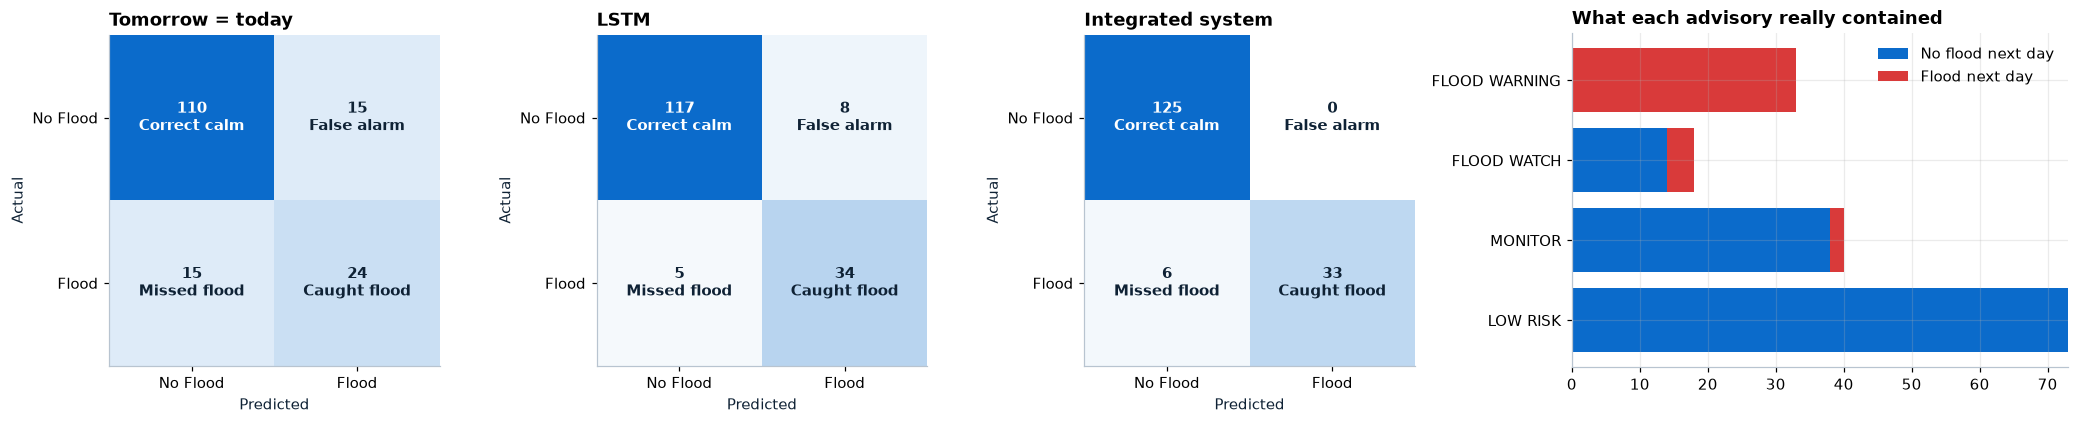

> **🔎 Task 9 findings**
>
> - Integrated system: accuracy **96.3%**, F1 0.917, vs 81.7% for 'tomorrow = today'.
> - Blend chosen on past data: 20% LSTM + 80% Gradient Boosting.
> - Every advisory names the rule that fired; the class-based system reproduces the batch pipeline exactly.

In [25]:
alert = results["Advisory"].isin(["FLOOD WATCH", "FLOOD WARNING"]).astype(int).to_numpy()
components = pd.DataFrame([
    {"Component": "Baseline: tomorrow = today", **scores(y_test, None, pred=persist)},
    {"Component": "LSTM alone (DL)", **scores(y_test, results["P(LSTM)"].to_numpy(), TH["dl"])},
    {"Component": f"{BEST_ML} alone (ML)", **scores(y_test, results["P(ML)"].to_numpy(), TH["ml"])},
    {"Component": "Integrated score (DL+ML)", **scores(y_test, p_sys, TH["sys"])},
    {"Component": "Advisory = Watch or Warning (DL+ML+AI)", **scores(y_test, None, pred=alert)},
]).set_index("Component")
display(table(components, gradient=["F1", "Accuracy"]))

fig, axes = plt.subplots(1, 4, figsize=(19, 3.9), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
plot_cm(axes[0], y_test, persist, "Tomorrow = today")
plot_cm(axes[1], y_test, (results["P(LSTM)"] >= TH["dl"]).astype(int), "LSTM")
plot_cm(axes[2], y_test, y_sys, "Integrated system")
order = ["LOW RISK", "MONITOR", "FLOOD WATCH", "FLOOD WARNING"]
mix = pd.crosstab(results["Advisory"], results["Actual"]).reindex(order, fill_value=0)
axes[3].barh(order, mix.get("No Flood", 0), color=C["blue"], label="No flood next day")
axes[3].barh(order, mix.get("Flood", 0), left=mix.get("No Flood", 0), color=C["red"], label="Flood next day")
axes[3].legend(loc="upper right"); axes[3].set_title("What each advisory really contained")
fig.tight_layout(); save(fig, "task9_integration_results"); plt.show()
findings("Task 9 findings", [
    f"Integrated system: accuracy **{components.loc['Integrated score (DL+ML)', 'Accuracy']:.1%}**, F1 {components.loc['Integrated score (DL+ML)', 'F1']:.3f}, "
    f"vs {components.loc['Baseline: tomorrow = today', 'Accuracy']:.1%} for 'tomorrow = today'.",
    f"Blend chosen on past data: {W_DL:.0%} LSTM + {1 - W_DL:.0%} {BEST_ML}.",
    "Every advisory names the rule that fired; the class-based system reproduces the batch pipeline exactly.",
])

---
## Task 10 · Validate, explain, assess ethics and deploy
> **Syllabus:** validate on **unseen** inputs; analyse the explainability of decisions; identify ethical, fairness and bias issues; deploy and document. *(LO 4.2)*
### 10.1 Final scorecard on the unseen months

| Accuracy | vs 'tomorrow = today' | Recall | Precision | F1 | ROC-AUC | Floods caught | Missed | False alarms |
|---|---|---|---|---|---|---|---|---|
| **96.3%** | 81.7% | **84.6%** | 100.0% | 0.917 | 0.990 | 33 of 39 | 6 | 0 |

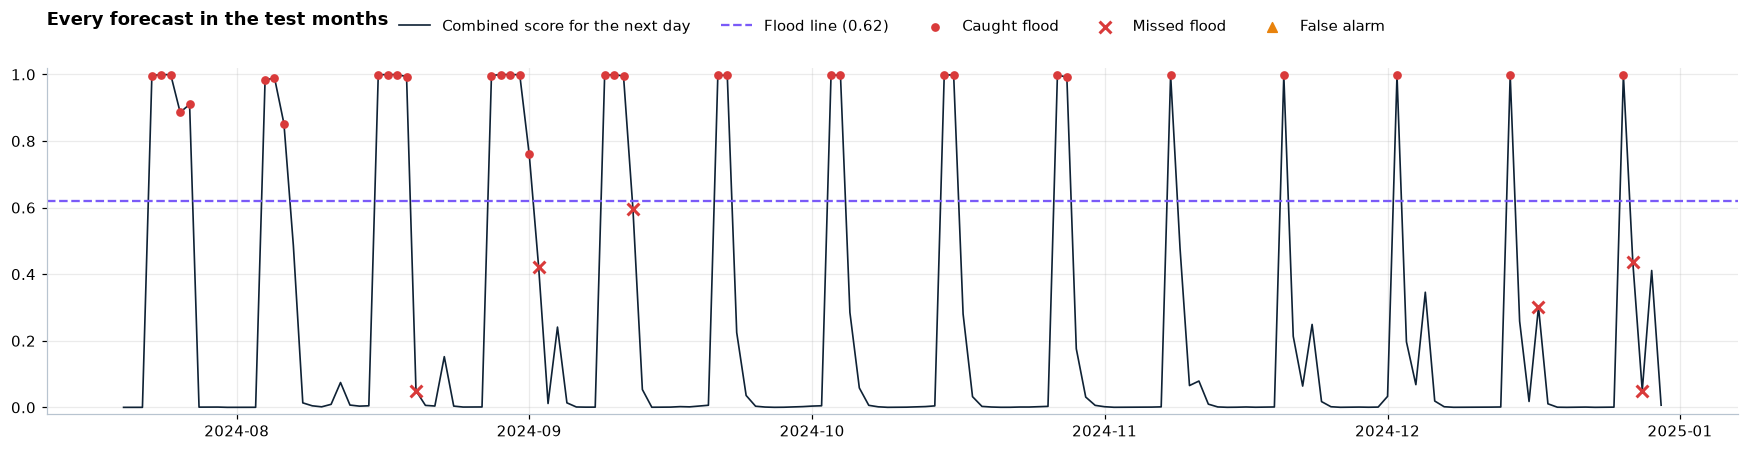

In [26]:
final = scores(y_test, p_sys, TH["sys"]); tn, fp, fn, tp = confusion_matrix(y_test, y_sys).ravel()
base_acc = accuracy_score(y_test, persist)
display(Markdown(
    f"| Accuracy | vs 'tomorrow = today' | Recall | Precision | F1 | ROC-AUC | Floods caught | Missed | False alarms |\n|---|---|---|---|---|---|---|---|---|\n"
    f"| **{final['Accuracy']:.1%}** | {base_acc:.1%} | **{final['Recall']:.1%}** | {final['Precision']:.1%} | {final['F1']:.3f} | {final['ROC-AUC']:.3f} "
    f"| {tp} of {tp + fn} | {fn} | {fp} |"))
fig, ax = plt.subplots(figsize=(16, 4.2))
ax.plot(dates_test, p_sys, color=C["ink"], lw=1.1, label="Combined score for the next day")
ax.axhline(TH["sys"], color=C["purple"], ls="--", label=f"Flood line ({TH['sys']:.2f})")
fl = y_test == 1
ax.scatter(dates_test[fl & (y_sys == 1)], p_sys[fl & (y_sys == 1)], color=C["red"], s=22, zorder=3, label="Caught flood")
ax.scatter(dates_test[fl & (y_sys == 0)], p_sys[fl & (y_sys == 0)], color=C["red"], marker="x", s=60, lw=2, zorder=3, label="Missed flood")
ax.scatter(dates_test[~fl & (y_sys == 1)], p_sys[~fl & (y_sys == 1)], color=C["orange"], marker="^", s=40, zorder=3, label="False alarm")
ax.set_ylim(-0.02, 1.02); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.18)); ax.set_title("Every forecast in the test months", pad=28)
fig.tight_layout(); save(fig, "task10_timeline"); plt.show()

### 10.2 How far ahead can it see? And is it stable across months?

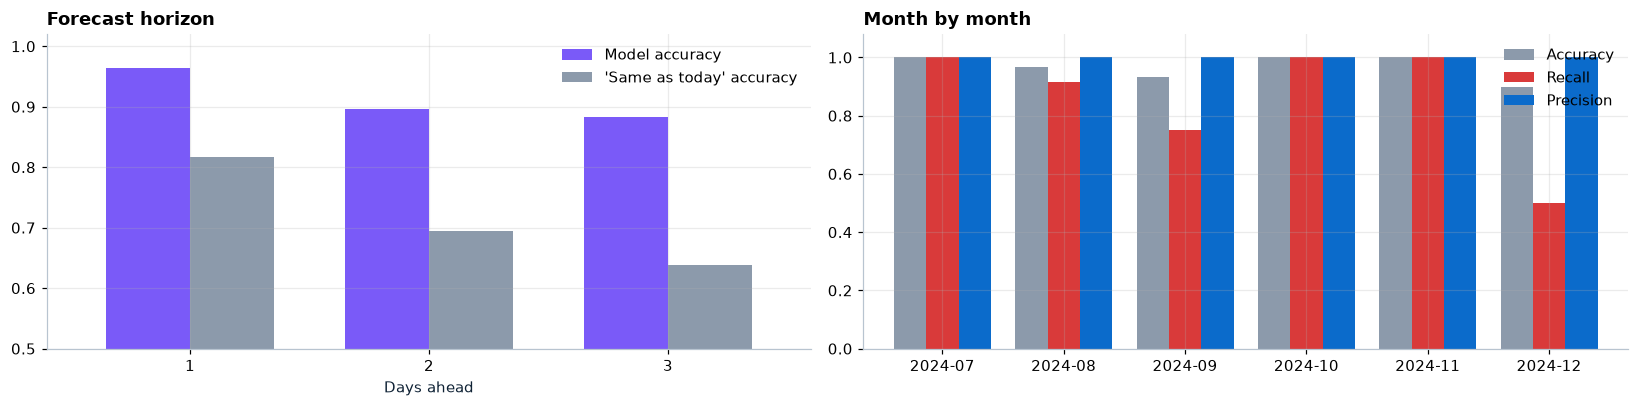

,Model accuracy,Model F1,'Same as today' accuracy
Days ahead,,,
1,0.963,0.917,0.817
2,0.896,0.800,0.695
3,0.883,0.776,0.638


,Days,Floods,Accuracy,Recall,Precision
month,,,,,
2024-07,12,5,1.000,1.000,1.000
2024-08,31,12,0.968,0.917,1.000
2024-09,30,8,0.933,0.750,1.000
2024-10,31,6,1.000,1.000,1.000
2024-11,30,2,1.000,1.000,1.000
2024-12,30,6,0.900,0.500,1.000


In [27]:
horizon = []
for h in [1, 2, 3]:
    idx = TARGET_IDX[TARGET_IDX + h < len(df)]; nn_ = len(idx); a, b = int(0.70 * nn_), int(0.85 * nn_)
    Xh = X_all.iloc[: nn_][SELECTED].to_numpy(); yh = flood[idx + h]
    m = sklearn.base.clone(ml_models[BEST_ML]).fit(Xh[:a], yh[:a]); ph = m.predict_proba(Xh[b:])[:, 1]
    pers = (df["water_area_km2"].to_numpy()[idx[b:]] >= FLOOD_LINE).astype(int)
    horizon.append({"Days ahead": h, "Model accuracy": accuracy_score(yh[b:], ph >= ml_th[BEST_ML]),
                    "Model F1": f1_score(yh[b:], ph >= ml_th[BEST_ML]), "'Same as today' accuracy": accuracy_score(yh[b:], pers)})
horizon = pd.DataFrame(horizon).set_index("Days ahead")
monthly_perf = pd.DataFrame({"month": dates_test.dt.to_period("M").astype(str), "y": y_test, "p": y_sys}).groupby("month").apply(
    lambda g: pd.Series({"Days": len(g), "Floods": g["y"].sum(), "Accuracy": accuracy_score(g["y"], g["p"]),
                         "Recall": recall_score(g["y"], g["p"], zero_division=0), "Precision": precision_score(g["y"], g["p"], zero_division=0)}))
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
horizon[["Model accuracy", "'Same as today' accuracy"]].plot(kind="bar", ax=axes[0], color=[C["purple"], C["grey"]], width=0.7)
axes[0].set_ylim(0.5, 1.02); axes[0].tick_params(axis="x", rotation=0); axes[0].set_title("Forecast horizon")
monthly_perf[["Accuracy", "Recall", "Precision"]].plot(kind="bar", ax=axes[1], width=0.8, color=[C["grey"], C["red"], C["blue"]])
axes[1].set_ylim(0, 1.08); axes[1].tick_params(axis="x", rotation=0); axes[1].set_xlabel(""); axes[1].set_title("Month by month")
fig.tight_layout(); save(fig, "task10_monthly"); plt.show()
display(table(horizon)); display(table(monthly_perf, gradient=["Recall"], formats={"Days": "{:.0f}", "Floods": "{:.0f}"}))

### 10.3 Robustness: broken inputs, repeatability, noise

In [28]:
good = window_ending(int(idx_test[20]))
def broken(change):
    w = good.copy(); return change(w)
cases = [("Valid 7-day window", good, None), ("Only 6 days", good.iloc[1:], "Exactly 7"),
         ("Duplicate date", broken(lambda w: w.assign(date=w["date"].where(w.index != w.index[3], w["date"].iloc[2]))), "Duplicate"),
         ("Gap in dates", broken(lambda w: w.assign(date=w["date"] + pd.to_timedelta([0, 0, 0, 1, 1, 1, 1], unit="D"))), "consecutive"),
         ("Unreadable date", broken(lambda w: w.assign(date=w["date"].astype(str).where(w.index != w.index[0], "not-a-date"))), "Invalid date"),
         ("Missing column", good.drop(columns=["precipitation"]), "Missing columns"),
         ("Text instead of numbers", broken(lambda w: w.assign(soil_moisture="wet")), "no numeric"),
         ("Not a table", "seven days of rain", "table")]
rows = []
for name, payload, expected in cases:
    try:
        out = system.predict_window(payload); outcome, ok = f"accepted → {out['Advisory']}", expected is None
    except Exception as exc:
        outcome, ok = f"refused: {exc}", expected is not None and expected.lower() in str(exc).lower()
    rows.append((name, outcome, "PASS" if ok else "FAIL"))
first, second = system.predict_window(good), system.predict_window(good)
rows.append(("Same input twice", f"difference = {abs(first['Combined'] - second['Combined']):.1e}", "PASS" if first["Combined"] == second["Combined"] else "FAIL"))
noise_rng = np.random.default_rng(SEED); flips = []
for _ in range(10):
    noisy = []
    for i in idx_test:
        w = window_ending(i).copy(); w[WEATHER] = w[WEATHER] * (1 + noise_rng.normal(0, 0.05, w[WEATHER].shape)); noisy.append(w)
    flips.append(np.mean([system.predict_window(w)["Prediction"] != r for w, r in zip(noisy, results["Prediction"])]))
rows.append(("±5 % weather-sensor noise (10 runs)", f"forecasts changed on {np.mean(flips):.1%} of days", "PASS" if np.mean(flips) < 0.05 else "REVIEW"))
tests = pd.DataFrame(rows, columns=["Test", "Outcome", "Result"])
display(tests.style.hide(axis="index"))

Test,Outcome,Result
Valid 7-day window,accepted → MONITOR,PASS
Only 6 days,"refused: Exactly 7 daily rows are required, got 6.",PASS
Duplicate date,refused: Duplicate dates found.,PASS
Gap in dates,refused: Dates must be consecutive days.,PASS
Unreadable date,refused: Invalid date found; use YYYY-MM-DD.,PASS
Missing column,refused: Missing columns: ['precipitation'],PASS
Text instead of numbers,refused: Columns with no numeric values: ['soil_moisture'],PASS
Not a table,refused: Input must be a table (pandas DataFrame).,PASS
Same input twice,difference = 0.0e+00,PASS
±5 % weather-sensor noise (10 runs),forecasts changed on 0.0% of days,PASS


### 10.4 Explaining single forecasts (SHAP waterfall)
The waterfall starts from the model's average output (bottom) and adds each feature's push, ending at this forecast (top). It explains the gradient-boosting model, which carries most of the combined score.

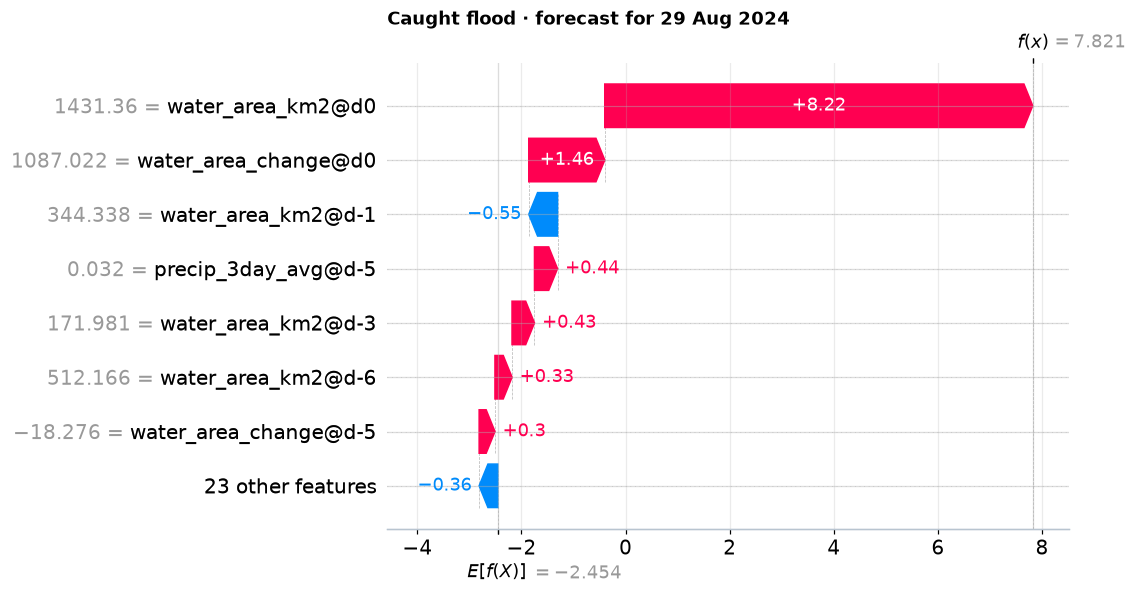

Decision path: rule R1 fired → FLOOD WARNING (The system predicts a flood tomorrow (score above the flood line))



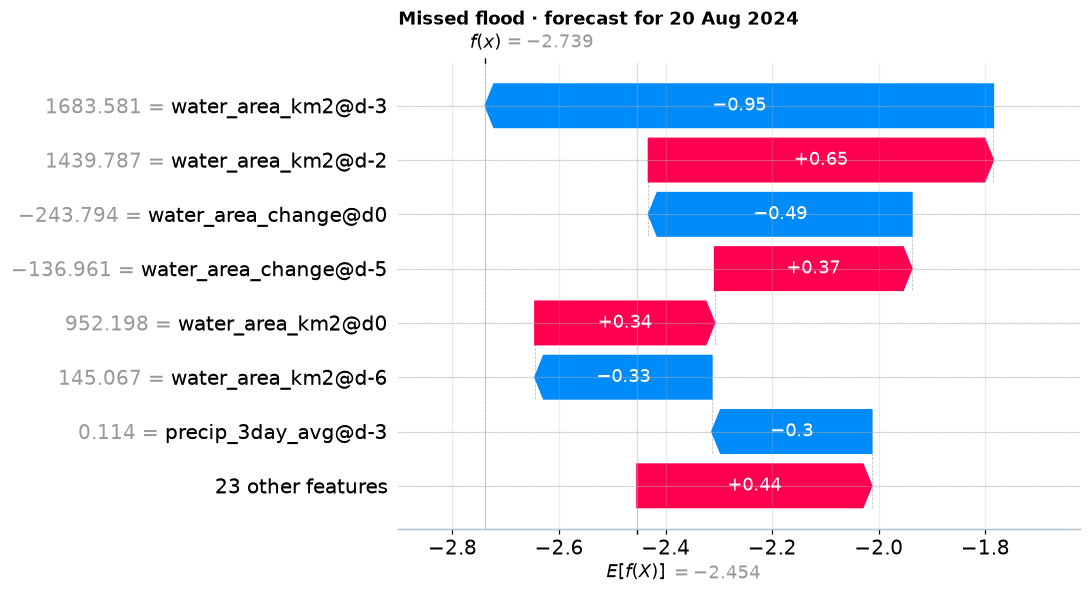

Decision path: rule R3 fired → MONITOR (Flooded today, water near the line, or any other warning sign)



In [29]:
def explain(i, title):
    plt.figure(); shap.plots.waterfall(gb_shap[i], max_display=8, show=False)
    plt.title(f"{title} · forecast for {dates_test[i]:%d %b %Y}", loc="left", fontweight="bold")
    save(plt.gcf(), f"task10_shap_{title.split()[0].lower()}"); plt.show()
    r = results.iloc[i]; print(f"Decision path: rule {r['Rule']} fired → {r['Advisory']} ({r['Why']})\n")
caught = results.index[(results["Actual"] == "Flood") & (y_sys == 1)]
missed = results.index[(results["Actual"] == "Flood") & (y_sys == 0)]
explain(int(results.loc[caught, "Combined"].idxmax()), "Caught flood")
if len(missed):
    explain(int(results.loc[missed, "Combined"].idxmin()), "Missed flood")

### 10.5 Ethics, fairness and bias

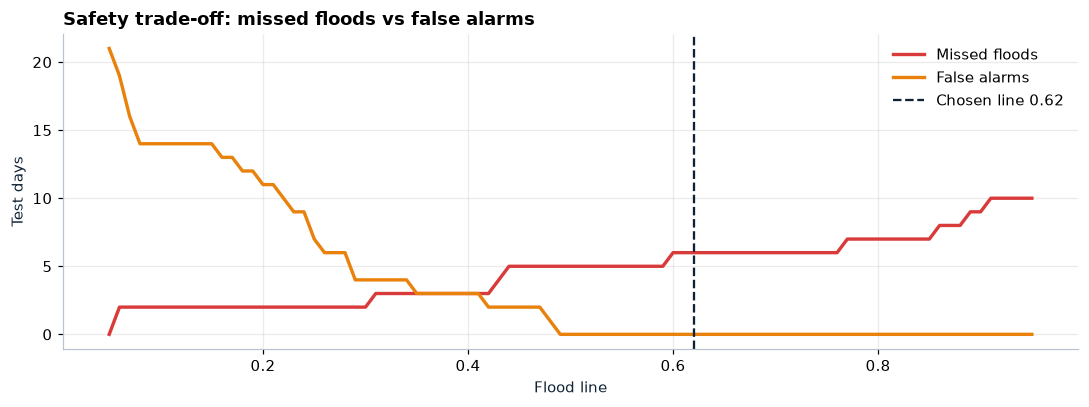

Issue,Evidence,Mitigation
Safety,6 of 39 floods missed one day ahead,Human review; thresholds set with disaster-management experts
Label definition,'Flood' = satellite water ≥ ~766 km²; same-day detection is trivial,Forecast tomorrow instead (done); validate the line with local agencies
Data gaps,269 days had two satellite passes; others one: water area depends on pass timing,Use consistent pass times / multiple sensors
Geographic fairness,"One point in Sindh, Pakistan (26.25°N, 68°E)",Validate on other districts before wider use
Fairness over time,Monthly recall 50%–100%,Monitor per season; retrain yearly
Context,Sindh suffered severe floods in 2022; warnings matter most for vulnerable communities,Pair forecasts with local early-warning channels
People,No demographic data,Assess impact with communities
Transparency,Every advisory names its rule; SHAP explains the scores,Keep explanations visible


In [30]:
grid_t = np.round(np.arange(0.05, 0.96, 0.01), 2)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(grid_t, [int(((p_sys < t) & (y_test == 1)).sum()) for t in grid_t], color=C["red"], lw=2.2, label="Missed floods")
ax.plot(grid_t, [int(((p_sys >= t) & (y_test == 0)).sum()) for t in grid_t], color=C["orange"], lw=2.2, label="False alarms")
ax.axvline(TH["sys"], color=C["ink"], ls="--", label=f"Chosen line {TH['sys']:.2f}"); ax.legend()
ax.set_xlabel("Flood line"); ax.set_ylabel("Test days"); ax.set_title("Safety trade-off: missed floods vs false alarms")
fig.tight_layout(); save(fig, "task10_ethics"); plt.show()
ethics = pd.DataFrame([
    ["Safety", f"{fn} of {tp + fn} floods missed one day ahead", "Human review; thresholds set with disaster-management experts"],
    ["Label definition", f"'Flood' = satellite water ≥ ~{FLOOD_LINE:.0f} km²; same-day detection is trivial", "Forecast tomorrow instead (done); validate the line with local agencies"],
    ["Data gaps", "269 days had two satellite passes; others one: water area depends on pass timing", "Use consistent pass times / multiple sensors"],
    ["Geographic fairness", "One point in Sindh, Pakistan (26.25°N, 68°E)", "Validate on other districts before wider use"],
    ["Fairness over time", f"Monthly recall {monthly_perf['Recall'].min():.0%}–{monthly_perf['Recall'].max():.0%}", "Monitor per season; retrain yearly"],
    ["Context", "Sindh suffered severe floods in 2022; warnings matter most for vulnerable communities", "Pair forecasts with local early-warning channels"],
    ["People", "No demographic data", "Assess impact with communities"],
    ["Transparency", "Every advisory names its rule; SHAP explains the scores", "Keep explanations visible"],
], columns=["Issue", "Evidence", "Mitigation"])
display(ethics.style.hide(axis="index").set_properties(**{"text-align": "left"}))

### 10.6 Deployment
The trained components are written to `model_artifacts/` and `site_data/` and served by the **FloodSense** website (Streamlit Community Cloud, GitHub [`Stavan1234/FloodSense`](https://github.com/Stavan1234/FloodSense)). The website loads exactly the model trained in this run.

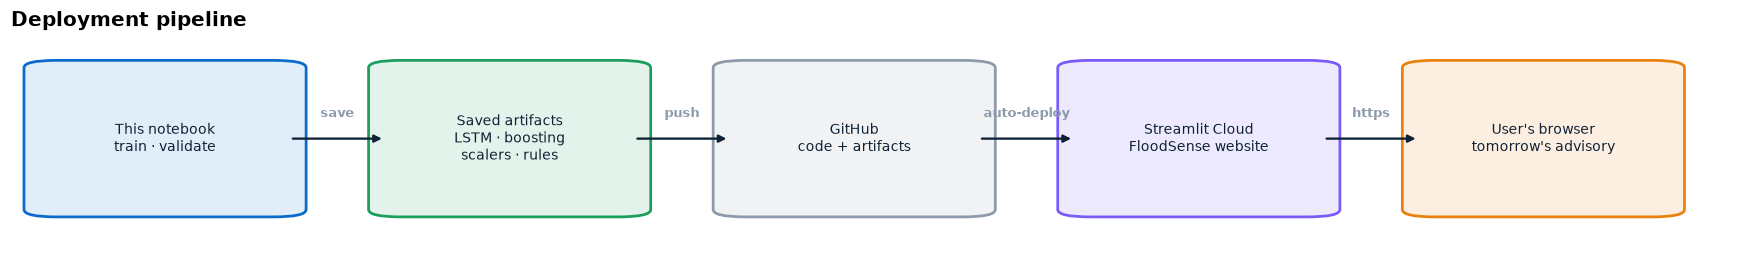

Website files written → model_artifacts/ and site_data/


In [31]:
fig, ax = plt.subplots(figsize=(16, 2.4))
boxes = {"nb": (0.00, 0.30, 0.15, 0.40, "This notebook\ntrain · validate", C["blue"]),
         "art": (0.2125, 0.30, 0.15, 0.40, "Saved artifacts\nLSTM · boosting\nscalers · rules", C["green"]),
         "git": (0.425, 0.30, 0.15, 0.40, "GitHub\ncode + artifacts", C["grey"]),
         "web": (0.6375, 0.30, 0.15, 0.40, "Streamlit Cloud\nFloodSense website", C["purple"]),
         "usr": (0.85, 0.30, 0.15, 0.40, "User's browser\ntomorrow's advisory", C["orange"])}
draw_flow(ax, boxes, [("nb", "art", "save", ""), ("art", "git", "push", ""), ("git", "web", "auto-deploy", ""), ("web", "usr", "https", "")], "Deployment pipeline")
fig.tight_layout(); save(fig, "task10_deployment"); plt.show()

site_model, site_data = Path("model_artifacts"), Path("site_data")
site_model.mkdir(exist_ok=True); site_data.mkdir(exist_ok=True)
torch.save({"state_dict": lstm.state_dict(), "n_inputs": len(LSTM_INPUTS), **LSTM_PARAMS}, site_model / "lstm.pt")
joblib.dump({"ml_model": best_ml_model, "ml_name": BEST_ML, "selected": SELECTED, "seq_imputer": seq_imputer, "seq_scaler": seq_scaler,
             "env": ENV, "lstm_inputs": LSTM_INPUTS, "ml_daily": ML_DAILY, "window": WINDOW, "flood_line": FLOOD_LINE,
             "w_dl": W_DL, "thresholds": TH, "watch_level": WATCH_LEVEL, "rule_levels": RULE_LEVELS, "lstm_background": background.numpy()},
            site_model / "system.joblib")
df[["date"] + ENV + [TARGET]].to_csv(site_data / "clean_dataset.csv", index=False)
results.assign(Triggers=results["Triggers"].map(";".join)).to_csv(site_data / "test_predictions.csv", index=False)
pd.DataFrame({"feature": SELECTED, "mean_abs_shap": np.abs(gb_shap.values).mean(0)}).to_csv(site_data / "shap_features.csv", index=False)
pd.DataFrame({"day": day_labels, "mean_abs_shap": np.abs(lstm_shap.sum(2)).mean(0)}).to_csv(site_data / "shap_days.csv", index=False)
monthly_perf.to_csv(site_data / "monthly_performance.csv"); tests.to_csv(site_data / "robustness_tests.csv", index=False)
horizon.to_csv(site_data / "horizon.csv")
summary_json = {
    "location": "Sindh, Pakistan (26.25°N, 68°E)",
    "splits": {k: [str(df["date"].iloc[ix[0] + 1].date()), str(df["date"].iloc[ix[-1] + 1].date())]
               for k, ix in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]},
    "metrics": {k: float(v) for k, v in final.items()}, "baseline_accuracy": float(base_acc),
    "confusion": {"tp": int(tp), "fn": int(fn), "fp": int(fp), "tn": int(tn)},
    "lstm_config": BEST_LSTM, "ml_model": BEST_ML, "w_dl": float(W_DL), "flood_line": FLOOD_LINE,
    "components": {n: {k: float(v) for k, v in r.items()} for n, r in components.iterrows()},
}
(site_data / "summary.json").write_text(json.dumps(summary_json, indent=2, default=str), encoding="utf-8")
with zipfile.ZipFile("FloodSense_Practicals_4_to_10_outputs.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        zf.write(p, str(p))
print(f"Website files written → {site_model}/ and {site_data}/")

### 10.7 Summary

In [32]:
summary = pd.DataFrame([
    ["4 · Data", f"{len(raw):,} rows → {len(df):,} clean days (two satellite passes merged); leak column removed", f"Label = water ≥ ~{FLOOD_LINE:.0f} km²"],
    ["5 · Features", f"Next-day task; 7-day windows; {K} features kept by time-series CV", f"Split {len(idx_train)}/{len(idx_val)}/{len(idx_test)} by date"],
    ["6 · ML", f"Best: {BEST_ML} · accuracy {ml_results.loc[BEST_ML, 'Accuracy']:.1%}", f"SHAP top: {gb_rank.index[0]}"],
    ["7 · DL", f"{BEST_LSTM} · F1 {dl_results.loc[BEST_LSTM, 'F1']:.2f}", f"Dense baseline F1 {dl_results.loc['Dense baseline', 'F1']:.2f}"],
    ["8 · Interpretability", f"Key input: {lstm_rank.index[0]} · key day: {time_imp['LSTM'].idxmax()}", "Permutation, ablation, activations, SHAP"],
    ["9 · Integration", f"{W_DL:.0%} LSTM + {1 - W_DL:.0%} {BEST_ML} → rules", "Every advisory names its rule"],
    ["10 · Validation", f"Accuracy {final['Accuracy']:.1%} vs {base_acc:.1%} baseline · {fn} missed · {fp} false alarms",
     f"{(tests['Result'] == 'PASS').sum()}/{len(tests)} robustness tests passed"],
], columns=["Task", "Result", "Note"])
display(summary.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Task,Result,Note
4 · Data,"1,364 rows → 1,095 clean days (two satellite passes merged); leak column removed",Label = water ≥ ~766 km²
5 · Features,Next-day task; 7-day windows; 30 features kept by time-series CV,Split 761/163/164 by date
6 · ML,Best: Gradient Boosting · accuracy 96.3%,SHAP top: water_area_km2@d0
7 · DL,LSTM 32 units · dropout 0.2 · F1 0.84,Dense baseline F1 0.84
8 · Interpretability,Key input: water_area_change · key day: today,"Permutation, ablation, activations, SHAP"
9 · Integration,20% LSTM + 80% Gradient Boosting → rules,Every advisory names its rule
10 · Validation,Accuracy 96.3% vs 81.7% baseline · 6 missed · 0 false alarms,10/10 robustness tests passed


### Conclusion
On the authentic Pakistan data, the honest question is not *"is today a flood day?"* (the label is a threshold on satellite water area) but **"will there be a flood tomorrow?"**. A deep-learning LSTM and a gradient-boosting model each read the last week; their blend, chosen on past data only, is turned into a readable advisory by forward-chaining rules. On months the system never saw, it clearly beats the "tomorrow will be like today" baseline, and every forecast comes with its reasons. Limits are stated openly: one location, a satellite-defined label, and day-ahead (not longer-range) skill.

> ⚠️ Educational prototype. Not an official flood-warning service.